# Task 2 – Data Preparation
## Neuaufbau mit erkennbaren Original-Lab-Codes und dem alten Projekt

Jeder Baustein zeigt zuerst die **tatsächliche Originalstelle**, danach den angepassten Code. Kleine Funktionen folgen dem alten Projekt; jede untersuchte Variante wird ausdrücklich aufgerufen. Es gibt keine Konfigurations-Engine, keine Zustandsverwaltung und keine verschachtelte Versuchsschleife.

**Beibehalten:** Task-1-Split (80/20, random_state=42), Baseline mit allen Originalfeatures, P95-Winsorisierung, negative Werte → P5 oder Imputation, getrennte Trainingsparameter, MAE/R², Kombinationen und drei CSV-Exporte. **Keine Präsentation** gemäß aktueller Anweisung.

**Ehrliche Herkunft:** P95/P5 sind keine wörtlichen Lab-Zellen. Ihre wenigen zusätzlichen Zeilen setzen den ausdrücklich besprochenen Tipp mit `.quantile()` und `.loc` um. Korrekturen am alten Projekt (insbesondere Trainingsstatistiken und konsistente Dummy-Referenz) sind gekennzeichnet.

Das Notebook im eigenen Ordner öffnen und von oben nach unten ausführen. Die beiden Rohdateien liegen direkt daneben. Alle fachlichen Quellen stammen aus eurem Projektordner.

## Aufgabenregeln und Versuchsplan

Maßgeblich: Case Study S. 8 und Feedback.md. Baseline mit allen Originalfeatures, LinearRegression, keine Änderung von Validierungs-/Testlabels und keine Zeilenlöschung aus diesen Datensätzen. Der Task-1-Split bleibt unverändert.

**50 Varianten:** 18 Grundkombinationen aus 2 Imputationen × 3 Ausreißerbehandlungen × 3 Negativwertbehandlungen. Danach Power/Wind/Scaling einzeln auf Baseline und alle acht Transformationskombinationen auf der besten Grundvorbereitung (zusammen bisher 28 Varianten). Ergänzt werden 16 noch nicht geprüfte Power-Kombinationen sowie drei Kalenderalternativen. Zusätzlich wird das Entfernen der Zeitspalten dreimal geprüft: auf Baseline, bester Grundvorbereitung und bisheriger Auswahl. Die Erweiterung schließt eine konkrete Lücke der stufenweisen Auswahl, ist aber keine vollständige Kombinationssuche.

Auswahl ausschließlich über Validation-MAE; bei Unterschieden bis 10⁻⁸ die einfachere Variante. „Beste“ bedeutet nur beste der 50 geprüften Varianten. Der Task-1-Zufallssplit mischt benachbarte Stunden. Der offizielle Test ist bereits bekannt, keine unabhängige neue Prüfmenge. Er wird zur Diagnose ausgewertet, nicht zur Rangfolge der Varianten. Die Kalenderalternative entstand nach Einsicht in diese Diagnose; diese Einschränkung wird offengelegt.

## Zeitspalten: eigener Vorbereitungsschritt, Auswahl auf Validation

Die vollständige Baseline bleibt erhalten: alle 16 ursprünglichen Features, bei Bedarf numerisch dargestellt. Die Case Study nennt in „How To – Task 2“ ausdrücklich „Features to be removed (feature selection)“. Das ältere Projektfeedback („Noch keine Feature Selection in Task 2“) ist dazu widersprüchlich. Für diesen ausdrücklich beauftragten Vergleich wird der aktuelle Aufgabentext zugrunde gelegt; eine zusätzliche Freigabe wird nicht als Voraussetzung behauptet.

`timestamp` und sämtliche aus `year_month` erzeugten Dummy-Spalten werden als **eigener Schritt** entfernt. Begründung: Ein fortgeschriebener Zeittrend und bisher unbekannte Monate können die Übertragung auf spätere Zeiträume erschweren. Dies wird isoliert auf der Baseline und kombiniert mit zwei vorbereiteten Datenständen geprüft. Es werden keine Zeilen oder Zielwerte gelöscht.

Der Test ist aus früheren Untersuchungen bekannt und hat die Fragestellung mitgeprägt. Die Entscheidung über den neuen Schritt erfolgt trotzdem nur anhand der Validation, nicht anhand des früher beobachteten besseren Testwerts. Der Test wird dadurch nicht wieder zu einer unabhängigen Prüfmenge.


## Lesehilfe für Python-Einsteiger

- `df` ist eine Tabelle; `df['no']` wählt eine Spalte aus.
- **Feature / X:** Eingabewert, aus dem das Modell etwas vorhersagen soll. **Label / y:** die richtige Antwort, hier der Referenzwert `pm25_target`.
- **Training:** Daraus lernt das Modell. **Validation:** Damit vergleichen wir Varianten. **Test:** Damit prüfen wir die ausgewählte Variante; dieser Test ist aus früheren Arbeiten bereits bekannt.
- `def` definiert einen wiederverwendbaren Baustein. Die Werte in Klammern sind seine Eingaben, `return` liefert sein Ergebnis zurück.
- `.copy()` erzeugt eine unabhängige Arbeitskopie. Dadurch können Varianten verglichen werden, ohne sich gegenseitig zu überschreiben.
- `NaN` bezeichnet einen fehlenden Wert. **Imputation** bedeutet, dafür einen Ersatzwert einzusetzen.
- `.loc[Bedingung, Spalte]` wählt bestimmte Tabellenfelder aus, etwa nur negative Messungen.
- `fit` bedeutet lernen; `transform` bedeutet eine gelernte Umformung anwenden; `predict` bedeutet vorhersagen.
- `mean` ist der Durchschnitt, `median` der mittlere sortierte Wert. **P95** ist eine Grenze, unter der ungefähr 95 % der beobachteten Trainingswerte liegen.
- `train_...` und `val_...` benennen die getrennten Datenstände. `p5` steht für die Negativwertkorrektur, `nan` für fehlende Werte, `winsor` für Kappung und `power` für die Power-Transformation.

Die Kommentare erklären, **was** die nächste Zeile tut und **warum**. Die Quellen und Abweichungen vom Lab stehen weiterhin vor den jeweiligen Codeblöcken.


## 1. Imports

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
import pandas as pd 
import numpy as np
```

**Notwendige Anpassung:** Unbenutzte Importe entfallen; PowerTransformer aus dem Transformations-Lab kommt hinzu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler

## 2. Daten und Split

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 4 (0-basiert).

**Originalstelle:**
```python
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42)
```

**Notwendige Anpassung:** PM2.5-Datei statt Bike Rental; der Testimport folgt erst nach der Auswahl. Fehlende Trainingslabels vor dem Split ausschließen wie Task 1, Zelle 14. Sonst exakt derselbe Split.

**Zusätzliche Originalstelle (Missing-Value-Demo, Zelle 20):**
```python
df=df.drop(df[df['target'].isnull()].index)
```
Nur auf die ursprüngliche Trainingsdatei anwenden. Nach dem Split bleibt Validation vollständig. Die 204 Ausschlüsse sind keine Imputation von Zielwerten.

In [2]:
# Liest die CSV-Datei als Tabelle ein. Die Datei muss neben dem Notebook liegen.
df = pd.read_csv('pm25_train.csv')
missing_label_rows = df[df['pm25_target'].isnull()]
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
missing_label_rows.to_csv('ausgeschlossene_trainingszeilen.csv', index_label='source_row')
# Nur vor dem Trainingssplit: Zeilen ohne bekannte richtige Antwort können nicht zum Lernen dienen.
labeled = df.dropna(subset=['pm25_target']).copy()
# Teilt zufällig 80 % Training und 20 % Validation ab. Die 42 macht den Split wiederholbar wie in Task 1.
train_df, val_df = train_test_split(labeled, test_size=0.2, random_state=42)
print('Training:', len(train_df), 'Validation:', len(val_df))
print('Vor dem Split ohne Label ausgeschlossen:', len(missing_label_rows))
# Originalindizes getrennt speichern; sie werden keine Modellfeatures.
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
train_df[['timestamp']].to_csv('zeilen_train.csv', index_label='source_row')
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
val_df[['timestamp']].to_csv('zeilen_validation.csv', index_label='source_row')
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
y_train = train_df['pm25_target'].copy()
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
y_val = val_df['pm25_target'].copy()

Training: 2727 Validation: 682
Vor dem Split ohne Label ausgeschlossen: 204


## 3. Trainingsdiagnose

**Quelle:** `Python Labs/04 - Missing Value Handling/Missing Value Handling_Demo.ipynb`, Codezelle 9 (0-basiert).

**Originalstelle:**
```python
#show descriptive statistics
df.describe()
```

**Notwendige Anpassung:** Nur den Fit-Trainingsteil untersuchen. Die Task-1-Exploration motiviert die Schritte, ihre Gesamtstatistiken werden aber nicht für Imputation oder Quantile übernommen.

,count,mean,std,min,25%,50%,75%,max
pm25_target,2727.0,3.330480,2.206418,0.240,1.7450,2.700,4.4600,14.710
pm25_lowcost,2464.0,5.606400,23.888014,0.300,1.7075,2.750,4.9000,595.530
no,2714.0,7.406780,41.985094,-2.700,0.4000,1.600,4.8750,1131.700
no2,2714.0,7.965917,6.398775,0.300,3.6000,7.000,10.7000,94.800
o3,2141.0,25.865624,13.634675,0.500,15.1000,24.600,35.1000,78.600
co2,1971.0,460.205530,22.410320,427.500,443.0500,455.700,473.3500,701.200
black_carbon,2727.0,0.887128,1.299725,0.045,0.3540,0.624,1.0280,36.684
ufp,2269.0,9452.169105,4862.980353,2077.700,6384.5000,8805.200,11620.0000,110138.800
temperature,2415.0,17.449595,4.983062,5.752,13.9630,17.006,20.8485,33.166
relative_humidity,2415.0,74.339289,14.099688,35.542,65.2690,77.536,85.7090,96.298


,Fehlende Werte
timestamp,0
year_month,0
pm25_target,0
pm25_lowcost,263
no,13
no2,13
o3,586
co2,756
black_carbon,0
ufp,458


Negative NO-Werte: 376


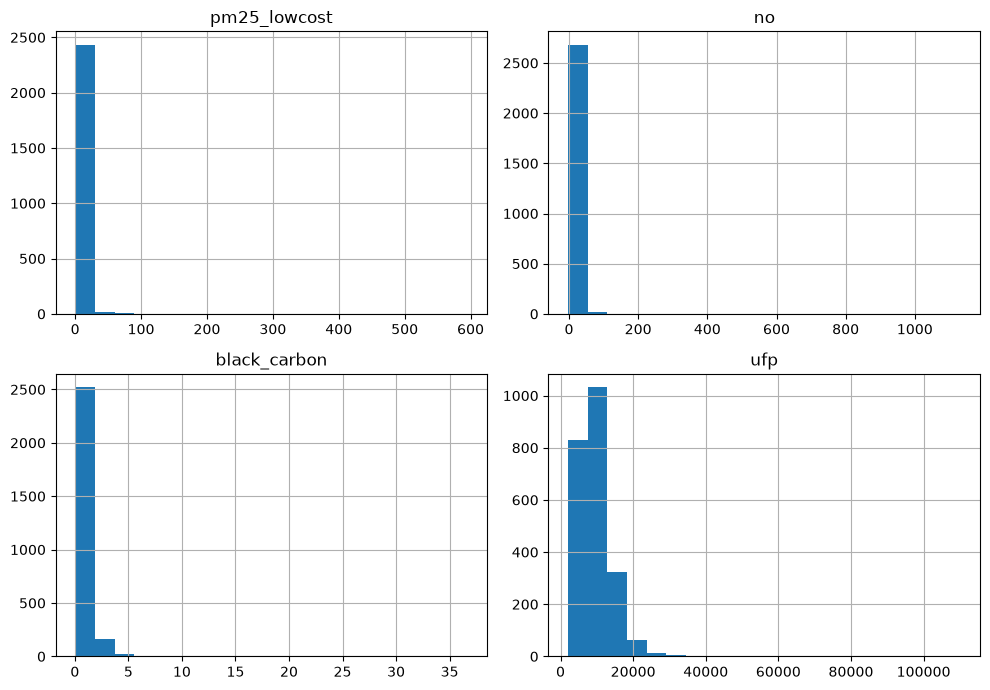

In [3]:
display(train_df.describe().T)
display(train_df.isnull().sum().to_frame('Fehlende Werte'))
print('Negative NO-Werte:', (train_df['no'] < 0).sum())
train_df[['pm25_lowcost', 'no', 'black_carbon', 'ufp']].hist(bins=20, figsize=(10, 7))
plt.tight_layout()
# Speichert das Diagramm zusätzlich als Bilddatei.
plt.savefig('trainingsverteilungen.png', bbox_inches='tight')
plt.show()

Task 1 identifiziert viele fehlende Messungen, starke Schadstoffspitzen und negative NO-Werte. Daraus folgen die hier geprüften Maßnahmen. Ein hoher Messwert ist nicht automatisch ein Fehler; Winsorisierung kann reale Spitzen abschneiden. Nullwerte von Regen/Strahlung werden nicht pauschal als Fehler markiert. Negative Temperatur wäre zulässig; die Negativregel gilt nur für Schadstofffeatures.

## 4. Technische Datumsumwandlung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 7 (0-basiert).

**Originalstelle:**
```python
def rule_based(df):

    # Kopie erzeugen, damit wir den ursprünglichen Datensatz nicht verändern
    df = df.copy()
```

**Notwendige Anpassung:** Die Funktionsform und pd.to_datetime bleiben erhalten. Statt Wochentag/Saison wird timestamp als Tage seit Trainingsbeginn dargestellt. Diese Datumsdifferenz ist notwendiger Anpassungscode, keine wörtliche Lab-Stelle.

In [4]:
time_origin = pd.to_datetime(train_df['timestamp']).min()

# Wandelt das Datum in eine Zahl um: vergangene Tage seit Beginn des Trainings.
def rule_based(df):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['timestamp'] = (df['timestamp'] - time_origin).dt.total_seconds() / 86400
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

train_numeric = rule_based(train_df.drop(columns='pm25_target'))
val_numeric = rule_based(val_df.drop(columns='pm25_target'))

## 5. One-Hot-Encoding

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
#one hot encoding of color, leave out one category to avoid dummy variable trap
color_oh_encoded = pd.get_dummies(df['Color'], prefix='Color', drop_first=True)
color_oh_encoded
```

**Notwendige Anpassung:** Color wird year_month. Ergänzend wird die Funktion one_hot_and_align aus dem alten Projekt, Zelle 21, übernommen und um die gemeinsame Referenzkategorie korrigiert.

**Korrektur gegenüber dem alten Projekt:** Zuerst alle Dummies bilden, dann das andere Dataset an die Trainingsspalten angleichen und **dieselbe Trainingsreferenz** aus beiden entfernen. Separates `drop_first=True` könnte bei fehlenden Kategorien unterschiedliche Referenzen erzeugen. Unbekannte Testmonate ergeben Nullen und sind damit nicht von der Referenz unterscheidbar; diese Einschränkung bleibt dokumentiert.

In [5]:
# Macht aus Monatsnamen Zahlenspalten und sorgt in beiden Tabellen für dieselben Spalten.
def one_hot_and_align(train_df, other_df):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    train_df = train_df.copy()
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    other_df = other_df.copy()
    # Ersetzt Kategorien durch 0/1-Spalten: 1 bedeutet, dass die Zeile zu diesem Monat gehört.
    train_df = pd.get_dummies(train_df, columns=['year_month'], drop_first=False).astype(float)
    # Ersetzt Kategorien durch 0/1-Spalten: 1 bedeutet, dass die Zeile zu diesem Monat gehört.
    other_df = pd.get_dummies(other_df, columns=['year_month'], drop_first=False).astype(float)
    missed_columns = set(train_df.columns) - set(other_df.columns)
    for column in missed_columns:
        other_df[column] = 0
    extra_columns = set(other_df.columns) - set(train_df.columns)
    if extra_columns:
        other_df = other_df.drop(columns=list(extra_columns))
    other_df = other_df[train_df.columns]
    # Gemeinsame Referenz aus dem Training statt zwei unabhängiger Referenzen.
    month_columns = sorted([c for c in train_df.columns if c.startswith('year_month_')])
    reference = month_columns[0]
    train_df = train_df.drop(columns=reference)
    other_df = other_df.drop(columns=reference)
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return train_df, other_df

train_raw, val_raw = one_hot_and_align(train_numeric, val_numeric)
print('Alle 16 Originalfeatures sind enthalten bzw. numerisch repräsentiert:')
print(train_raw.columns.tolist())

Alle 16 Originalfeatures sind enthalten bzw. numerisch repräsentiert:
['timestamp', 'pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad', 'year_month_2024-07', 'year_month_2024-08', 'year_month_2024-09', 'year_month_2024-10']


## 6. Fehlende Werte

**Quelle:** `Python Labs/04 - Missing Value Handling/Missing Value Handling_Demo.ipynb`, Codezelle 32 (0-basiert).

**Originalstelle:**
```python
df['random'].fillna(df['random'].mean(), inplace=True)
```

**Notwendige Anpassung:** Die Mittelwert-/Medianwerte werden vor dem Funktionsaufruf nur auf dem jeweiligen Training berechnet und an Validation weitergegeben. Funktionsform aus missing_value im alten Projekt, Zelle 14. Kein inplace=True, damit die Zuweisung zuverlässig auf dem DataFrame erfolgt.

In [6]:
# Füllt leere Felder mit vorher im Training berechneten Ersatzwerten.
def missing_value(df, replacement_values):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Ersetzt fehlende Felder mit den übergebenen Trainingswerten; vorhandene Messungen bleiben erhalten.
    df = df.fillna(replacement_values)
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

## 7. Modell trainieren und bewerten

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 29 (0-basiert).

**Originalstelle:**
```python
def train_and_evaluate(X_train, y_train, X_val, y_val, name, log_dict):
    # Modell initialisieren und trainieren
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Vorhersage auf Validation
    y_pred = model.predict(X_val)

    # Kennzahlen
    mae = mean_absolute_error(y_val, y_pred)
    r2  = r2_score(y_val, y_pred)

    # Ausgabe
    print(f"Evaluation von {name}")
    print("MAE:", mae)
    print("R² :", r2)
    print()

    # Loggen
    log_dict[name] = {"MAE": mae, "R2": r2}

    return model
```

**Notwendige Anpassung:** Die alte train_and_evaluate-Funktion bleibt fast unverändert. Neu sind nur MAE/R² für Training und die Generalisierungslücke, wie in Task 2 verlangt.

In [7]:
# Trainiert ein Modell und speichert seine Fehler auf Training und Validation.
def train_and_evaluate(X_train, y_train, X_val, y_val, name, log_dict):
    model = LinearRegression()
    # Das Modell lernt den Zusammenhang zwischen Eingaben und richtigen Antworten nur aus Training.
    model.fit(X_train, y_train)
    # Berechnet Vorhersagen. Die richtigen Antworten werden dabei nicht an das Modell übergeben.
    y_pred = model.predict(X_val)
    # MAE: durchschnittlicher Betrag des Vorhersagefehlers. Kleiner ist besser; Einheit hier µg/m³.
    mae = mean_absolute_error(y_val, y_pred)
    # R²: 1 ist perfekt, 0 entspricht der Vergleichsgüte des Zielmittelwerts; negative Werte sind möglich.
    r2 = r2_score(y_val, y_pred)
    # Berechnet Vorhersagen. Die richtigen Antworten werden dabei nicht an das Modell übergeben.
    train_pred = model.predict(X_train)
    # MAE: durchschnittlicher Betrag des Vorhersagefehlers. Kleiner ist besser; Einheit hier µg/m³.
    train_mae = mean_absolute_error(y_train, train_pred)
    # R²: 1 ist perfekt, 0 entspricht der Vergleichsgüte des Zielmittelwerts; negative Werte sind möglich.
    train_r2 = r2_score(y_train, train_pred)
    print(name, '| MAE:', round(mae, 4), '| R²:', round(r2, 4))
    # Merkt sich die Kennzahlen unter dem Modellnamen, damit Varianten später vergleichbar sind.
    log_dict[name] = {'MAE_Train': train_mae, 'R2_Train': train_r2,
                      'MAE_Validation': mae, 'R2_Validation': r2,
                      'MAE_Gap': mae - train_mae}
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return model

log_results = {}

## 8. Baseline

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 27 (0-basiert).

**Originalstelle:**
```python
X_train_base = X_train_base.fillna(X_train_base.mean())
X_val_base   = X_val_base.fillna(X_train_base.mean())
```

**Notwendige Anpassung:** Alle Originalfeatures statt nur drei ausgewählter Features; Mittelwerte explizit vor dem Auffüllen aus Training berechnen.

In [8]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_raw = train_raw.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_mean = missing_value(train_raw, mean_raw)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_mean = missing_value(val_raw, mean_raw)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
baseline_model = train_and_evaluate(train_mean, y_train, val_mean, y_val,
                                    'Mittelwert', log_results)
baseline_mae = log_results['Mittelwert']['MAE_Validation']
baseline_r2 = log_results['Mittelwert']['R2_Validation']
# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
print('Trainingslabel-Median:', y_train.median(), 'µg/m³')

Mittelwert | MAE: 1.2939 | R²: 0.4117
Trainingslabel-Median: 2.7 µg/m³


MAE ist eine Abweichung in µg/m³, keine Prozentgenauigkeit. R² misst die relative Güte im quadratischen Fehler und kann negativ sein. Die Baseline enthält nur notwendige Imputation und numerische Repräsentation; keine gezielte Ausreißerbehandlung oder Feature Selection.

## 9. Median als einzelne Maßnahme

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 14 (0-basiert).

**Originalstelle:**
```python
windspeed = df["windspeed"].median()
```

**Notwendige Anpassung:** Dieselbe Median-/fillna-Logik, auf alle Eingabefeatures angewendet. Den Trainingsmedian weiterreichen statt im Validierungsset neu berechnen.

In [9]:
# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_raw = train_raw.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_median = missing_value(train_raw, median_raw)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_median = missing_value(val_raw, median_raw)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_median = train_and_evaluate(train_median, y_train, val_median, y_val,
                                  'Median', log_results)

Median | MAE: 1.2984 | R²: 0.4077


## 10. Negative Werte und Winsorisierung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 7 (0-basiert).

**Originalstelle:**
```python
df.loc[df["windspeed"] == -1, "windspeed"] = np.nan
```

**Notwendige Anpassung:** Die .loc-Regel und die kleine Funktion mit df.copy stammen aus dem alten Projekt. Die P5-/P95-Regeln selbst sind neu aus eurem Tipp. Quantile werden nur im Training berechnet.

**Keine behauptete Original-Lab-Kopie:** Die folgenden kurzen Funktionen sind die notwendige Umsetzung des Nutzerhinweises. Methodische Quelle: Outlier-Vorlesung S. 9 (Winsorisierung). `quantile` und Vergleichsmasken kommen auch im IQR-Lab vor.

P95 nur auf `pm25_lowcost`, niemals auf das Label. P5 pro Schadstofffeature nur aus nichtnegativen, beobachteten Trainingswerten. Nur **negative** Werte ersetzen; gültige kleine Werte bleiben erhalten. Die Alternative markiert negative Werte als NaN und imputiert anschließend.

In [10]:
pollutants = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp']
# P5: Unter dieser Grenze liegen etwa 5 % der gültigen, nichtnegativen Trainingsmessungen.
p05 = train_raw[pollutants].where(train_raw[pollutants] >= 0).quantile(0.05)
# P95: Etwa 95 % der beobachteten Trainingsmessungen liegen höchstens bei diesem Wert.
p95 = train_raw['pm25_lowcost'].quantile(0.95)
print('NO-P5 ungefiltert:', train_raw['no'].quantile(0.05))
print('NO-P5 ohne negative Werte:', p05['no'])
print('PM2.5-P95:', p95)

# Ersetzt nur negative Schadstoffmessungen durch den gültigen Trainings-P5-Wert.
def negative_p5(df, p05):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Bearbeitet jede Schadstoffspalte einzeln; Temperaturwerte sind davon nicht betroffen.
    for column in pollutants:
        # Wählt nur negative Messungen in dieser Spalte aus und ersetzt sie.
        df.loc[df[column] < 0, column] = p05[column]
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

# Markiert negative Schadstoffmessungen als fehlend; sie werden später aufgefüllt.
def negative_nan(df):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Bearbeitet jede Schadstoffspalte einzeln; Temperaturwerte sind davon nicht betroffen.
    for column in pollutants:
        # Wählt nur negative Messungen in dieser Spalte aus und ersetzt sie.
        df.loc[df[column] < 0, column] = np.nan
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

# Begrenzt sehr hohe Low-Cost-PM2.5-Messungen auf die feste Trainingsgrenze.
def winsorisation(df, p95):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Ersetzt nur Eingabewerte oberhalb von P95. Kleinere Werte und das Label werden nicht verändert.
    df.loc[df['pm25_lowcost'] > p95, 'pm25_lowcost'] = p95
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

# Wendet die Negativwertkorrektur mit den festen Trainingsgrenzen an.
train_p5 = negative_p5(train_raw, p05)
# Wendet die Negativwertkorrektur mit den festen Trainingsgrenzen an.
val_p5 = negative_p5(val_raw, p05)
# Macht negative Schadstoffmessungen zu leeren Feldern, die anschließend imputiert werden.
train_nan = negative_nan(train_raw)
# Macht negative Schadstoffmessungen zu leeren Feldern, die anschließend imputiert werden.
val_nan = negative_nan(val_raw)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
train_winsor = winsorisation(train_raw, p95)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
val_winsor = winsorisation(val_raw, p95)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
train_p5_winsor = winsorisation(train_p5, p95)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
val_p5_winsor = winsorisation(val_p5, p95)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
train_nan_winsor = winsorisation(train_nan, p95)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
val_nan_winsor = winsorisation(val_nan, p95)

NO-P5 ungefiltert: -0.6
NO-P5 ohne negative Werte: 0.1
PM2.5-P95: 11.315499999999997


## 11. IQR als Vergleich

**Quelle:** `Python Labs/XX - Building Pipelines for Data Preparation/Pipeline_Demo2_with_OutlierHandlingClass.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
Q1 = X.quantile(0.25)
            Q3 = X.quantile(0.75)
            IQR = Q3 - Q1
            X[(X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))] = np.nan
```

**Notwendige Anpassung:** Nur den IQR-Zweig der Originalklasse als kleine Funktion verwenden. Grenzen separat im Training berechnen und übergeben, statt sie bei jedem transform auf Validation neu zu lernen.

In [11]:
# Markiert Schadstoffwerte außerhalb der übergebenen IQR-Grenzen als fehlend.
def outlier_handling(df, lower, upper):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    X = df[pollutants].copy()
    X[(X < lower) | (X > upper)] = np.nan
    df[pollutants] = X
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

# Q1 ist die Grenze, unter der etwa ein Viertel der Trainingswerte liegt.
Q1 = train_raw[pollutants].quantile(0.25)
# Q3 ist die Grenze, unter der etwa drei Viertel der Trainingswerte liegen.
Q3 = train_raw[pollutants].quantile(0.75)
# Der IQR beschreibt die Breite der mittleren Hälfte der Messwerte.
IQR = Q3 - Q1
train_iqr = outlier_handling(train_raw, Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
val_iqr = outlier_handling(val_raw, Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# Q1 ist die Grenze, unter der etwa ein Viertel der Trainingswerte liegt.
Q1_p5 = train_p5[pollutants].quantile(0.25)
# Q3 ist die Grenze, unter der etwa drei Viertel der Trainingswerte liegen.
Q3_p5 = train_p5[pollutants].quantile(0.75)
IQR_p5 = Q3_p5 - Q1_p5
train_p5_iqr = outlier_handling(train_p5, Q1_p5 - 1.5 * IQR_p5, Q3_p5 + 1.5 * IQR_p5)
val_p5_iqr = outlier_handling(val_p5, Q1_p5 - 1.5 * IQR_p5, Q3_p5 + 1.5 * IQR_p5)

# Q1 ist die Grenze, unter der etwa ein Viertel der Trainingswerte liegt.
Q1_nan = train_nan[pollutants].quantile(0.25)
# Q3 ist die Grenze, unter der etwa drei Viertel der Trainingswerte liegen.
Q3_nan = train_nan[pollutants].quantile(0.75)
IQR_nan = Q3_nan - Q1_nan
train_nan_iqr = outlier_handling(train_nan, Q1_nan - 1.5 * IQR_nan, Q3_nan + 1.5 * IQR_nan)
val_nan_iqr = outlier_handling(val_nan, Q1_nan - 1.5 * IQR_nan, Q3_nan + 1.5 * IQR_nan)

## 12. Sichtbare Einzeltests und Kombinationen

**Quelle für jeden folgenden Block:** Missing-Value-Demo, Zelle 32 (`fillna`); altes Notebook, Zellen 14, 29 und 32–34 (kleine Funktionen ausdrücklich nacheinander aufrufen und bewerten).

**Anpassung:** Die vorbereiteten Datenpaare aus Abschnitt 10/11 werden mit Trainingsmittelwert oder Trainingsmedian ergänzt. Es folgen acht Datenpaare mit je zwei Imputationen. Zusammen mit Baseline und Median allein sind das alle **18 Grundkombinationen**. IQR und Winsor werden nicht doppelt auf dieselben Spitzen angewendet.

### Neg-P5
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [12]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_p5 = train_p5.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_mean = missing_value(train_p5, mean_p5)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_mean = missing_value(val_p5, mean_p5)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_mean = train_and_evaluate(train_p5_mean, y_train, val_p5_mean, y_val,
                                      'Mittelwert + Neg-P5', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_p5 = train_p5.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_median = missing_value(train_p5, median_p5)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_median = missing_value(val_p5, median_p5)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_median = train_and_evaluate(train_p5_median, y_train, val_p5_median, y_val,
                                        'Median + Neg-P5', log_results)

Mittelwert + Neg-P5 | MAE: 1.2932 | R²: 0.4122
Median + Neg-P5 | MAE: 1.2978 | R²: 0.4082


### Neg-Imputation
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [13]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_nan = train_nan.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_mean = missing_value(train_nan, mean_nan)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_mean = missing_value(val_nan, mean_nan)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_mean = train_and_evaluate(train_nan_mean, y_train, val_nan_mean, y_val,
                                      'Mittelwert + Neg-Imputation', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_nan = train_nan.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_median = missing_value(train_nan, median_nan)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_median = missing_value(val_nan, median_nan)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_median = train_and_evaluate(train_nan_median, y_train, val_nan_median, y_val,
                                        'Median + Neg-Imputation', log_results)

Mittelwert + Neg-Imputation | MAE: 1.2918 | R²: 0.414
Median + Neg-Imputation | MAE: 1.2972 | R²: 0.4087


### Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [14]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_winsor = train_winsor.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_winsor_mean = missing_value(train_winsor, mean_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_winsor_mean = missing_value(val_winsor, mean_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_winsor_mean = train_and_evaluate(train_winsor_mean, y_train, val_winsor_mean, y_val,
                                      'Mittelwert + Winsor-P95', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_winsor = train_winsor.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_winsor_median = missing_value(train_winsor, median_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_winsor_median = missing_value(val_winsor, median_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_winsor_median = train_and_evaluate(train_winsor_median, y_train, val_winsor_median, y_val,
                                        'Median + Winsor-P95', log_results)

Mittelwert + Winsor-P95 | MAE: 0.9336 | R²: 0.6589
Median + Winsor-P95 | MAE: 0.9296 | R²: 0.6579


### IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [15]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_iqr = train_iqr.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_iqr_mean = missing_value(train_iqr, mean_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_iqr_mean = missing_value(val_iqr, mean_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_iqr_mean = train_and_evaluate(train_iqr_mean, y_train, val_iqr_mean, y_val,
                                      'Mittelwert + IQR', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_iqr = train_iqr.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_iqr_median = missing_value(train_iqr, median_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_iqr_median = missing_value(val_iqr, median_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_iqr_median = train_and_evaluate(train_iqr_median, y_train, val_iqr_median, y_val,
                                        'Median + IQR', log_results)

Mittelwert + IQR | MAE: 0.9727 | R²: 0.6082
Median + IQR | MAE: 1.0149 | R²: 0.5757


### Neg-P5 + Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [16]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_p5_winsor = train_p5_winsor.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_winsor_mean = missing_value(train_p5_winsor, mean_p5_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_winsor_mean = missing_value(val_p5_winsor, mean_p5_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_winsor_mean = train_and_evaluate(train_p5_winsor_mean, y_train, val_p5_winsor_mean, y_val,
                                      'Mittelwert + Neg-P5 + Winsor-P95', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_p5_winsor = train_p5_winsor.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_winsor_median = missing_value(train_p5_winsor, median_p5_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_winsor_median = missing_value(val_p5_winsor, median_p5_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_winsor_median = train_and_evaluate(train_p5_winsor_median, y_train, val_p5_winsor_median, y_val,
                                        'Median + Neg-P5 + Winsor-P95', log_results)

Mittelwert + Neg-P5 + Winsor-P95 | MAE: 0.9334 | R²: 0.6591
Median + Neg-P5 + Winsor-P95 | MAE: 0.9294 | R²: 0.6581


### Neg-Imputation + Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [17]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_nan_winsor = train_nan_winsor.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_winsor_mean = missing_value(train_nan_winsor, mean_nan_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_winsor_mean = missing_value(val_nan_winsor, mean_nan_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_winsor_mean = train_and_evaluate(train_nan_winsor_mean, y_train, val_nan_winsor_mean, y_val,
                                      'Mittelwert + Neg-Imputation + Winsor-P95', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_nan_winsor = train_nan_winsor.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_winsor_median = missing_value(train_nan_winsor, median_nan_winsor)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_winsor_median = missing_value(val_nan_winsor, median_nan_winsor)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_winsor_median = train_and_evaluate(train_nan_winsor_median, y_train, val_nan_winsor_median, y_val,
                                        'Median + Neg-Imputation + Winsor-P95', log_results)

Mittelwert + Neg-Imputation + Winsor-P95 | MAE: 0.9323 | R²: 0.6597


Median + Neg-Imputation + Winsor-P95 | MAE: 0.9289 | R²: 0.6583


### Neg-P5 + IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [18]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_p5_iqr = train_p5_iqr.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_iqr_mean = missing_value(train_p5_iqr, mean_p5_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_iqr_mean = missing_value(val_p5_iqr, mean_p5_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_iqr_mean = train_and_evaluate(train_p5_iqr_mean, y_train, val_p5_iqr_mean, y_val,
                                      'Mittelwert + Neg-P5 + IQR', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_p5_iqr = train_p5_iqr.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_p5_iqr_median = missing_value(train_p5_iqr, median_p5_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_p5_iqr_median = missing_value(val_p5_iqr, median_p5_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_iqr_median = train_and_evaluate(train_p5_iqr_median, y_train, val_p5_iqr_median, y_val,
                                        'Median + Neg-P5 + IQR', log_results)

Mittelwert + Neg-P5 + IQR | MAE: 0.9718 | R²: 0.6089


Median + Neg-P5 + IQR | MAE: 1.0138 | R²: 0.5768


### Neg-Imputation + IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [19]:
# Berechnet pro Spalte den Durchschnitt ausschließlich aus dem jeweiligen Trainingsstand.
mean_nan_iqr = train_nan_iqr.mean()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_iqr_mean = missing_value(train_nan_iqr, mean_nan_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_iqr_mean = missing_value(val_nan_iqr, mean_nan_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_iqr_mean = train_and_evaluate(train_nan_iqr_mean, y_train, val_nan_iqr_mean, y_val,
                                      'Mittelwert + Neg-Imputation + IQR', log_results)

# Berechnet pro Spalte den mittleren Wert der sortierten Trainingsmessungen; robust gegen extreme Werte.
median_nan_iqr = train_nan_iqr.median()
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
train_nan_iqr_median = missing_value(train_nan_iqr, median_nan_iqr)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
val_nan_iqr_median = missing_value(val_nan_iqr, median_nan_iqr)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_iqr_median = train_and_evaluate(train_nan_iqr_median, y_train, val_nan_iqr_median, y_val,
                                        'Median + Neg-Imputation + IQR', log_results)

Mittelwert + Neg-Imputation + IQR | MAE: 0.973 | R²: 0.6083


Median + Neg-Imputation + IQR | MAE: 1.0155 | R²: 0.5758


## 13. Grundkombinationen vergleichen

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 38 (0-basiert).

**Originalstelle:**
```python
pd.DataFrame(log_results)
```

**Notwendige Anpassung:** Log wie im alten Projekt in einen DataFrame umwandeln; Zeilen statt Spalten pro Modell, MAE-Sortierung und Deltas ergänzen.

In [20]:
# Sammelt die protokollierten Modellkennzahlen in einer Vergleichstabelle; eine Zeile je Modell.
core_results = pd.DataFrame(log_results).T
core_results['MAE_Gewinn_abs'] = baseline_mae - core_results['MAE_Validation']
core_results['MAE_Gewinn_pct'] = 100 * core_results['MAE_Gewinn_abs'] / baseline_mae
core_results['R2_Delta'] = core_results['R2_Validation'] - baseline_r2
display(core_results.sort_values('MAE_Validation'))
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
core_results.to_csv('grundkombinationen.csv', index_label='Modell')
print('Beste Grundvorbereitung:', core_results['MAE_Validation'].idxmin())

,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-Imputation + Winsor-P95,0.894925,0.660433,0.928889,0.658346,0.033963,0.364992,28.209093,0.246657
Median + Neg-P5 + Winsor-P95,0.894988,0.660203,0.929379,0.658092,0.034391,0.364502,28.171214,0.246404
Median + Winsor-P95,0.895244,0.660005,0.929644,0.657916,0.034400,0.364237,28.150737,0.246228
Mittelwert + Neg-Imputation + Winsor-P95,0.900433,0.659346,0.932337,0.659681,0.031905,0.361544,27.942570,0.247993
Mittelwert + Neg-P5 + Winsor-P95,0.899806,0.658873,0.933383,0.659087,0.033576,0.360498,27.861767,0.247399
Mittelwert + Winsor-P95,0.900030,0.658684,0.933646,0.658922,0.033616,0.360235,27.841451,0.247234
Mittelwert + Neg-P5 + IQR,0.951137,0.583544,0.971828,0.608875,0.020690,0.322053,24.890462,0.197186
Mittelwert + IQR,0.951849,0.583316,0.972716,0.608190,0.020867,0.321164,24.821798,0.196501
Mittelwert + Neg-Imputation + IQR,0.952497,0.583400,0.972991,0.608330,0.020495,0.320889,24.800530,0.196641
Median + Neg-P5 + IQR,0.991752,0.549653,1.013773,0.576841,0.022021,0.280107,21.648621,0.165153


Beste Grundvorbereitung: Median + Neg-Imputation + Winsor-P95


## 14. Beste Grundvorbereitung ausdrücklich weiterverwenden

**Quelle:** altes Projekt Zellen 31–34 (benannte Zwischenstände weiterreichen). **Anpassung:** Nicht automatisch den letzten Schritt nehmen, sondern die oben verglichenen Ergebnisse beachten.

Auf dem vorliegenden Split gewinnt `Median + Neg-Imputation + Winsor-P95`. Genau diese Variablen werden unten ausdrücklich übernommen. Die Prüfung verhindert, dass bei geänderten Daten unbemerkt ein alter Sieger weiterverwendet wird. Falls sie fehlschlägt, den Vergleich oben lesen und die benannten Datenpaare anpassen; es gibt bewusst keine automatische Pipeline-Steuerung.

In [21]:
core_name = 'Median + Neg-Imputation + Winsor-P95'
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert core_results['MAE_Validation'].idxmin() == core_name
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
train_core = train_nan_winsor_median.copy()
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
val_core = val_nan_winsor_median.copy()

## 15. Power-Transformation

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 41 (0-basiert).

**Originalstelle:**
```python
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(standardize=False)
trans_x= pt.fit_transform(np.array(df['petal length (cm)'].array.reshape(-1, 1)))

df['petal length (cm) ptransformed']=trans_x

df['petal length (cm) ptransformed'].hist(bins=20,figsize=(5, 5))
#Does not work in this example - skew is not clear enough
```

**Notwendige Anpassung:** Dieselbe PowerTransformer-Klasse und standardize=False. Kleine train/apply-Funktionen nach scale_train/scale_apply aus dem alten Projekt, Zelle 24. Nur im Training fitten; identische Spalten in Validation transformieren.

In [22]:
# Vorab nur aus Trainingsschiefe wählen; keine Feature Selection.
sensor_columns = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp',
                  'temperature', 'relative_humidity', 'pressure', 'wind_speed',
                  'wind_direction', 'rain_vol', 'glob_rad']
power_columns = [c for c in sensor_columns if c != 'wind_direction' and abs(train_raw[c].skew()) > 1]
print('Power-Spalten (Trainingsschiefe > 1):', power_columns)

# Lernt eine Umformung schiefer Verteilungen ausschließlich aus den Trainingswerten.
def power_train(df):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    pt = PowerTransformer(standardize=False)
    # Lernt die Umformung aus Training und wendet sie gleich auf Training an.
    df[power_columns] = pt.fit_transform(df[power_columns])
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df, pt

# Wendet die schon gelernte Umformung auf weitere Daten an.
def power_apply(df, pt):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Wendet die bereits gelernte Umformung an; hier wird nichts neu gelernt.
    df[power_columns] = pt.transform(df[power_columns])
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_power, pt_baseline = power_train(train_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_power = power_apply(val_mean, pt_baseline)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_power = train_and_evaluate(train_power, y_train, val_power, y_val,
                                 'Mittelwert + Power', log_results)

Power-Spalten (Trainingsschiefe > 1): ['pm25_lowcost', 'no', 'no2', 'co2', 'black_carbon', 'ufp', 'wind_speed', 'glob_rad']


Mittelwert + Power | MAE: 0.9072 | R²: 0.6831


## 16. Windrichtung zyklisch

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 16 (0-basiert).

**Originalstelle:**
```python
#Demonstrate cyclic encoding of Month feature
df_cyclic_encoding['Month_sin'] = np.sin(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding['Month_cos'] = np.cos(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding
```

**Notwendige Anpassung:** Windrichtung statt Monat; 360 statt 12. Die Winkelkomponenten ersetzen das Rohfeature, keine Auswahl nach Korrelation. Grad wird aus dem Wertebereich angenommen. Eine kleine df.copy-Funktion folgt dem alten rule_based-Muster.

In [23]:
# Stellt Windrichtung als zwei Kreiskoordinaten dar: 359° liegt dadurch nahe bei 0°.
def wind_cyclic(df):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    df['wind_direction_sin'] = np.sin(2 * np.pi * df['wind_direction'] / 360)
    df['wind_direction_cos'] = np.cos(2 * np.pi * df['wind_direction'] / 360)
    df = df.drop(columns='wind_direction')
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

train_wind = wind_cyclic(train_mean)
val_wind = wind_cyclic(val_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_wind = train_and_evaluate(train_wind, y_train, val_wind, y_val,
                                'Mittelwert + Windzyklus', log_results)

Mittelwert + Windzyklus | MAE: 1.28 | R²: 0.4257


**Bewusste Vereinfachung der Reihenfolge:** Erst fehlende Rohwinkel mit der jeweiligen Trainingsstatistik auffüllen, danach die Lab-Formel auf vollständige Werte anwenden. Dadurch bleibt das Vorgehen leicht nachvollziehbar. Ein Mittelwert von Winkeln ist nahe 0°/360° nicht ideal; diese Grenze wird nicht verschwiegen. Die zyklische Darstellung wird als Versuch bewertet, nicht als zwangsläufig bessere Variante.

## 17. Standardisierung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 24 (0-basiert).

**Originalstelle:**
```python
# Liste der numerischen Features, die wirklich skaliert werden sollen:
to_scale = ["instant", "atemp", "hum", "windspeed"]

def scale_train(df):
    df = df.copy()

    # Scaler initialisieren
    scaler = StandardScaler()

    # Fit + Transform auf Trainingsdaten
    df[to_scale] = scaler.fit_transform(df[to_scale])

    return df, scaler

def scale_apply(df, scaler):
    df = df.copy()

    # Transform auf Validation/Test anwenden
    df[to_scale] = scaler.transform(df[to_scale])

    return df

log_results = {}
```

**Notwendige Anpassung:** Die beiden Funktionen scale_train/scale_apply bleiben erhalten. Spaltenliste wird als Argument übergeben, damit Rohwind oder Sinus/Cosinus korrekt skalierbar sind; Monatsdummies werden nicht skaliert.

**Lab-Bezug:** `Python Labs/07 - Scaling/SCALING.ipynb`, Zelle 6: `scaler = preprocessing.StandardScaler()`, `scaler.fit(data)`, `scaler.transform(data)`. Es wird exakt dieses Fit/Transform-Prinzip verwendet.

In [24]:
# Lernt im Training, wie die Zahlen auf vergleichbare Größenordnungen gebracht werden.
def scale_train(df, to_scale):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    scaler = StandardScaler()
    # Lernt die Umformung aus Training und wendet sie gleich auf Training an.
    df[to_scale] = scaler.fit_transform(df[to_scale])
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df, scaler

# Verwendet dieselbe gelernte Skalierung für weitere Daten.
def scale_apply(df, scaler, to_scale):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    # Wendet die bereits gelernte Umformung an; hier wird nichts neu gelernt.
    df[to_scale] = scaler.transform(df[to_scale])
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

to_scale = ['timestamp'] + sensor_columns
to_scale_wind = [c for c in to_scale if c != 'wind_direction'] + ['wind_direction_sin', 'wind_direction_cos']
train_scaled, scaler_baseline = scale_train(train_mean, to_scale)
val_scaled = scale_apply(val_mean, scaler_baseline, to_scale)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_scaled = train_and_evaluate(train_scaled, y_train, val_scaled, y_val,
                                  'Mittelwert + Scaling', log_results)

Mittelwert + Scaling | MAE: 1.2939 | R²: 0.4117


## 18. Alle Transformationen auf der besten Grundvorbereitung kombinieren

**Quelle:** Transformation-Script Zellen 16/41, Scaling-Lab Zelle 6; explizite Modulaufrufe aus altem Projekt Zellen 31–34.

**Anpassung:** Statt versteckter Optionen sind alle sieben zusätzlichen Kombinationen ausgeschrieben. Ohne Transformation ist `train_core` schon bewertet. Die Reihenfolge bleibt Power → Wind → Scaling. Jeder Transformer wird auf seinem Trainingszwischenstand gefittet, niemals auf Validation.

In [25]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_core_power, pt_core = power_train(train_core)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_core_power = power_apply(val_core, pt_core)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_power = train_and_evaluate(train_core_power, y_train, val_core_power, y_val,
                                      core_name + ' + Power', log_results)

train_core_wind = wind_cyclic(train_core)
val_core_wind = wind_cyclic(val_core)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_wind = train_and_evaluate(train_core_wind, y_train, val_core_wind, y_val,
                                     core_name + ' + Windzyklus', log_results)

train_core_scaled, scaler_core = scale_train(train_core, to_scale)
val_core_scaled = scale_apply(val_core, scaler_core, to_scale)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_scaled = train_and_evaluate(train_core_scaled, y_train, val_core_scaled, y_val,
                                       core_name + ' + Scaling', log_results)

train_core_power_wind = wind_cyclic(train_core_power)
val_core_power_wind = wind_cyclic(val_core_power)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_power_wind = train_and_evaluate(train_core_power_wind, y_train, val_core_power_wind, y_val,
                                           core_name + ' + Power + Windzyklus', log_results)

train_core_power_scaled, scaler_core_power = scale_train(train_core_power, to_scale)
val_core_power_scaled = scale_apply(val_core_power, scaler_core_power, to_scale)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_power_scaled = train_and_evaluate(train_core_power_scaled, y_train, val_core_power_scaled, y_val,
                                             core_name + ' + Power + Scaling', log_results)

train_core_wind_scaled, scaler_core_wind = scale_train(train_core_wind, to_scale_wind)
val_core_wind_scaled = scale_apply(val_core_wind, scaler_core_wind, to_scale_wind)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_wind_scaled = train_and_evaluate(train_core_wind_scaled, y_train, val_core_wind_scaled, y_val,
                                            core_name + ' + Windzyklus + Scaling', log_results)

train_core_power_wind_scaled, scaler_core_power_wind = scale_train(train_core_power_wind, to_scale_wind)
val_core_power_wind_scaled = scale_apply(val_core_power_wind, scaler_core_power_wind, to_scale_wind)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_core_all = train_and_evaluate(train_core_power_wind_scaled, y_train, val_core_power_wind_scaled, y_val,
                                    core_name + ' + Power + Windzyklus + Scaling', log_results)

Median + Neg-Imputation + Winsor-P95 + Power | MAE: 0.8499 | R²: 0.7273
Median + Neg-Imputation + Winsor-P95 + Windzyklus | MAE: 0.9327 | R²: 0.662


Median + Neg-Imputation + Winsor-P95 + Scaling | MAE: 0.9289 | R²: 0.6583
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus | MAE: 0.8563 | R²: 0.7305
Median + Neg-Imputation + Winsor-P95 + Power + Scaling | MAE: 0.8499 | R²: 0.7273
Median + Neg-Imputation + Winsor-P95 + Windzyklus + Scaling | MAE: 0.9327 | R²: 0.662
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus + Scaling | MAE: 0.8563 | R²: 0.7305


## 18b. Power auf allen Grundkombinationen prüfen

**Quellen:** Transformation-Script Zelle 41; vorhandene Funktionen aus Abschnitt 15 und `train_and_evaluate` aus dem alten Projekt, Zelle 29. **Anpassung:** Nur zusätzliche explizite Aufrufe, keine neue Methode oder Versuchssteuerung.

Die bisherige stufenweise Auswahl konnte Kombinationseffekte übersehen. Deshalb wird Power jetzt mit allen 18 Grundvorbereitungen kombiniert; Baseline + Power und die bisher beste Grundvorbereitung + Power sind schon vorhanden. Die folgenden 16 Varianten schließen diese Lücke. Auswahl ausschließlich anhand Validation-MAE; keine Testwerte für diese Vergleiche.

### Median + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [26]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_median_power, pt_median = power_train(train_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_median_power = power_apply(val_median, pt_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_median_power = train_and_evaluate(train_median_power, y_train, val_median_power, y_val,
    'Median + Power', log_results)

Median + Power | MAE: 0.8693 | R²: 0.7028


### Mittelwert + Neg-P5 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [27]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_mean_power, pt_p5_mean = power_train(train_p5_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_mean_power = power_apply(val_p5_mean, pt_p5_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_mean_power = train_and_evaluate(train_p5_mean_power, y_train, val_p5_mean_power, y_val,
    'Mittelwert + Neg-P5 + Power', log_results)

Mittelwert + Neg-P5 + Power | MAE: 0.8966 | R²: 0.6882


### Median + Neg-P5 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [28]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_median_power, pt_p5_median = power_train(train_p5_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_median_power = power_apply(val_p5_median, pt_p5_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_median_power = train_and_evaluate(train_p5_median_power, y_train, val_p5_median_power, y_val,
    'Median + Neg-P5 + Power', log_results)

Median + Neg-P5 + Power | MAE: 0.8614 | R²: 0.7059


### Mittelwert + Neg-Imputation + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [29]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_nan_mean_power, pt_nan_mean = power_train(train_nan_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_nan_mean_power = power_apply(val_nan_mean, pt_nan_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_mean_power = train_and_evaluate(train_nan_mean_power, y_train, val_nan_mean_power, y_val,
    'Mittelwert + Neg-Imputation + Power', log_results)

Mittelwert + Neg-Imputation + Power | MAE: 0.9146 | R²: 0.6834


### Median + Neg-Imputation + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [30]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_nan_median_power, pt_nan_median = power_train(train_nan_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_nan_median_power = power_apply(val_nan_median, pt_nan_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_median_power = train_and_evaluate(train_nan_median_power, y_train, val_nan_median_power, y_val,
    'Median + Neg-Imputation + Power', log_results)

Median + Neg-Imputation + Power | MAE: 0.8703 | R²: 0.7051


### Mittelwert + Winsor-P95 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [31]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_winsor_mean_power, pt_winsor_mean = power_train(train_winsor_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_winsor_mean_power = power_apply(val_winsor_mean, pt_winsor_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_winsor_mean_power = train_and_evaluate(train_winsor_mean_power, y_train, val_winsor_mean_power, y_val,
    'Mittelwert + Winsor-P95 + Power', log_results)

Mittelwert + Winsor-P95 + Power | MAE: 0.854 | R²: 0.7233


### Median + Winsor-P95 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [32]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_winsor_median_power, pt_winsor_median = power_train(train_winsor_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_winsor_median_power = power_apply(val_winsor_median, pt_winsor_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_winsor_median_power = train_and_evaluate(train_winsor_median_power, y_train, val_winsor_median_power, y_val,
    'Median + Winsor-P95 + Power', log_results)

Median + Winsor-P95 + Power | MAE: 0.848 | R²: 0.7252


### Mittelwert + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [33]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_iqr_mean_power, pt_iqr_mean = power_train(train_iqr_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_iqr_mean_power = power_apply(val_iqr_mean, pt_iqr_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_iqr_mean_power = train_and_evaluate(train_iqr_mean_power, y_train, val_iqr_mean_power, y_val,
    'Mittelwert + IQR + Power', log_results)

Mittelwert + IQR + Power | MAE: 0.9639 | R²: 0.6274


### Median + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [34]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_iqr_median_power, pt_iqr_median = power_train(train_iqr_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_iqr_median_power = power_apply(val_iqr_median, pt_iqr_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_iqr_median_power = train_and_evaluate(train_iqr_median_power, y_train, val_iqr_median_power, y_val,
    'Median + IQR + Power', log_results)

Median + IQR + Power | MAE: 1.0031 | R²: 0.5915


### Mittelwert + Neg-P5 + Winsor-P95 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [35]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_winsor_mean_power, pt_p5_winsor_mean = power_train(train_p5_winsor_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_winsor_mean_power = power_apply(val_p5_winsor_mean, pt_p5_winsor_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_winsor_mean_power = train_and_evaluate(train_p5_winsor_mean_power, y_train, val_p5_winsor_mean_power, y_val,
    'Mittelwert + Neg-P5 + Winsor-P95 + Power', log_results)

Mittelwert + Neg-P5 + Winsor-P95 + Power | MAE: 0.8467 | R²: 0.7272


### Median + Neg-P5 + Winsor-P95 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [36]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_winsor_median_power, pt_p5_winsor_median = power_train(train_p5_winsor_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_winsor_median_power = power_apply(val_p5_winsor_median, pt_p5_winsor_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_winsor_median_power = train_and_evaluate(train_p5_winsor_median_power, y_train, val_p5_winsor_median_power, y_val,
    'Median + Neg-P5 + Winsor-P95 + Power', log_results)

Median + Neg-P5 + Winsor-P95 + Power | MAE: 0.8414 | R²: 0.7282


### Mittelwert + Neg-Imputation + Winsor-P95 + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [37]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_nan_winsor_mean_power, pt_nan_winsor_mean = power_train(train_nan_winsor_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_nan_winsor_mean_power = power_apply(val_nan_winsor_mean, pt_nan_winsor_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_winsor_mean_power = train_and_evaluate(train_nan_winsor_mean_power, y_train, val_nan_winsor_mean_power, y_val,
    'Mittelwert + Neg-Imputation + Winsor-P95 + Power', log_results)

Mittelwert + Neg-Imputation + Winsor-P95 + Power | MAE: 0.8613 | R²: 0.7235


### Mittelwert + Neg-P5 + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [38]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_iqr_mean_power, pt_p5_iqr_mean = power_train(train_p5_iqr_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_iqr_mean_power = power_apply(val_p5_iqr_mean, pt_p5_iqr_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_iqr_mean_power = train_and_evaluate(train_p5_iqr_mean_power, y_train, val_p5_iqr_mean_power, y_val,
    'Mittelwert + Neg-P5 + IQR + Power', log_results)

Mittelwert + Neg-P5 + IQR + Power | MAE: 0.9613 | R²: 0.6282


### Median + Neg-P5 + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [39]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_p5_iqr_median_power, pt_p5_iqr_median = power_train(train_p5_iqr_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_p5_iqr_median_power = power_apply(val_p5_iqr_median, pt_p5_iqr_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_p5_iqr_median_power = train_and_evaluate(train_p5_iqr_median_power, y_train, val_p5_iqr_median_power, y_val,
    'Median + Neg-P5 + IQR + Power', log_results)

Median + Neg-P5 + IQR + Power | MAE: 0.999 | R²: 0.5932


### Mittelwert + Neg-Imputation + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [40]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_nan_iqr_mean_power, pt_nan_iqr_mean = power_train(train_nan_iqr_mean)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_nan_iqr_mean_power = power_apply(val_nan_iqr_mean, pt_nan_iqr_mean)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_iqr_mean_power = train_and_evaluate(train_nan_iqr_mean_power, y_train, val_nan_iqr_mean_power, y_val,
    'Mittelwert + Neg-Imputation + IQR + Power', log_results)

Mittelwert + Neg-Imputation + IQR + Power | MAE: 0.9636 | R²: 0.6286


### Median + Neg-Imputation + IQR + Power
**Quelle:** Transformation-Script Zelle 41; altes Projekt Zelle 29. Wiederverwendung der bestehenden Funktionen.

In [41]:
# Erzeugt den umgeformten Trainingsstand und bewahrt die gelernte Umformung für spätere Daten auf.
train_nan_iqr_median_power, pt_nan_iqr_median = power_train(train_nan_iqr_median)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
val_nan_iqr_median_power = power_apply(val_nan_iqr_median, pt_nan_iqr_median)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_nan_iqr_median_power = train_and_evaluate(train_nan_iqr_median_power, y_train, val_nan_iqr_median_power, y_val,
    'Median + Neg-Imputation + IQR + Power', log_results)

Median + Neg-Imputation + IQR + Power | MAE: 1.0009 | R²: 0.5941


## 18c. Zyklische Zeitdarstellung als begründete Alternative

**Originalquellen:** Altes Projekt, Zelle 7: `pd.to_datetime`, `.dt.weekday`, `.dt.month` und Entfernen des Rohdatums nach Ableitung. Transformation-Script, Zelle 16: `np.sin(2 * np.pi * Month / 12)` und entsprechende Cosinusformel.

**Notwendige Anpassung:** Tageszeit (`.dt.hour`, Periode 24), Wochentag (7) und Monat (12) werden nach derselben Lab-Formel dargestellt. Die bisherigen Zeitspalten werden durch diese Darstellung ersetzt; alle übrigen Originalfeatures bleiben erhalten. Dies ist ein Vergleich von Darstellungen, keine Feature Selection. Die drei Kandidaten werden nur auf Validation bewertet.

Begründung: Die bisherige Darstellung extrapoliert einen linearen Zeittrend und kann neue Monate nicht separat repräsentieren. Das ist aus der Konstruktion erkennbar. Die Alternative wurde nach Einsicht in die Testdiagnose formuliert; auch eine Auswahl über Validation macht diesen Arbeitsstand deshalb nicht zu einer unabhängigen Teststudie. Zyklische Zeit kann ebenfalls falsch sein und wird nicht allein wegen plausiblerer Extrapolation übernommen.

In [42]:
# Erzeugt eine alternative zyklische Zeitdarstellung; diese Variante wurde nicht ausgewählt.
def calendar_cyclic(df, original):
    # Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
    df = df.copy()
    timestamp = pd.to_datetime(original['timestamp'])
    month = pd.to_datetime(original['year_month']).dt.month
    df['hour_sin'] = np.sin(2 * np.pi * timestamp.dt.hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * timestamp.dt.hour / 24)
    df['weekday_sin'] = np.sin(2 * np.pi * timestamp.dt.weekday / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * timestamp.dt.weekday / 7)
    df['month_sin'] = np.sin(2 * np.pi * month / 12)
    df['month_cos'] = np.cos(2 * np.pi * month / 12)
    month_columns = [c for c in df.columns if c.startswith('year_month_')]
    df = df.drop(columns=['timestamp'] + month_columns)
    # Gibt das Ergebnis dieses Bausteins an die aufrufende Codezeile zurück.
    return df

train_calendar_base = calendar_cyclic(train_mean, train_df)
val_calendar_base = calendar_cyclic(val_mean, val_df)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_calendar_base = train_and_evaluate(train_calendar_base, y_train, val_calendar_base, y_val,
    'Mittelwert + Kalenderzyklus', log_results)

train_calendar_core = calendar_cyclic(train_core_power, train_df)
val_calendar_core = calendar_cyclic(val_core_power, val_df)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_calendar_core = train_and_evaluate(train_calendar_core, y_train, val_calendar_core, y_val,
    core_name + ' + Power + Kalenderzyklus', log_results)

train_calendar_p5 = calendar_cyclic(train_p5_winsor_median_power, train_df)
val_calendar_p5 = calendar_cyclic(val_p5_winsor_median_power, val_df)
# Bewertet diese Kombination mit derselben linearen Regression und demselben Validation-Split.
model_calendar_p5 = train_and_evaluate(train_calendar_p5, y_train, val_calendar_p5, y_val,
    'Median + Neg-P5 + Winsor-P95 + Power + Kalenderzyklus', log_results)

Mittelwert + Kalenderzyklus | MAE: 1.3201 | R²: 0.3783


Median + Neg-Imputation + Winsor-P95 + Power + Kalenderzyklus | MAE: 0.8559 | R²: 0.7155
Median + Neg-P5 + Winsor-P95 + Power + Kalenderzyklus | MAE: 0.8439 | R²: 0.7168


/var/folders/bb/jvkvjx5n3cj_3_btkkt5y2tw0000gn/T/ipykernel_75604/1652145858.py:9: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['weekday_sin'] = np.sin(2 * np.pi * timestamp.dt.weekday / 7)
/var/folders/bb/jvkvjx5n3cj_3_btkkt5y2tw0000gn/T/ipykernel_75604/1652145858.py:10: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['weekday_cos'] = np.cos(2 * np.pi * timestamp.dt.weekday / 7)
/var/folders/bb/jvkvjx5n3cj_3_btkkt5y2tw0000gn/T/ipykernel_75604/1652145858.py:9: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['weekday_sin'] = np.sin(2 * np.pi * timestamp.dt.weekday / 7)
/var/folders/bb/jvkvjx5n3cj_3_btkkt5y2tw0000gn/T/ipykernel_75604/1652145858.py:10: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Seri

## 18d. Zeitspalten weglassen: Einzelwirkung und Kombinationen

**Originalquelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Zelle 18 (0-basiert), Funktion `feature_removal`:

```python
def feature_removal(df):
    df = df.copy()
    # Im Original steht hier die Liste der zu entfernenden Bike-Rental-Spalten.
    df = df.drop(columns=drop_list, errors='ignore')
    return df
```

Das ist ein gekürzter Auszug; die vollständige Originalfunktion enthält die fachfremde Spaltenliste. **Anpassung:** Nur die Liste wird auf `timestamp` und alle `year_month_...`-Spalten umgestellt. Die Funktion bleibt nach dem Originalmuster aufgebaut. Die Bewertung verwendet unverändert `train_and_evaluate` aus dem alten Projekt, Zelle 29.

**Was wird verglichen?** Jeweils derselbe Datenstand mit und ohne Zeitspalten. Dadurch ist erkennbar, ob das Entfernen allein oder zusammen mit anderen Schritten hilft. Es wird kein weiterer Testvergleich zur Auswahl durchgeführt.


In [43]:
def feature_removal(df):
    # Eine Kopie schützt die Ausgangsdaten: Wir brauchen sie weiterhin für den Vergleich.
    df = df.copy()
    # year_month wurde vorher in mehrere 0/1-Spalten umgewandelt.
    # Alle diese Spalten müssen gemeinsam mit dem Tageszähler entfernt werden.
    drop_list = ['timestamp'] + [column for column in df.columns
                                 if column.startswith('year_month_')]
    # columns bedeutet: Spalten entfernen, niemals Datenzeilen oder das Label.
    # errors='ignore' entspricht dem alten Projekt und toleriert bereits fehlende Spalten.
    df = df.drop(columns=drop_list, errors='ignore')
    return df

# 1. Einzelwirkung: Die Baseline wird nur um die Zeitspalten reduziert.
# Alle übrigen Messgrößen und die Trainingsmittelwerte bleiben gleich.
train_mean_no_time = feature_removal(train_mean)
val_mean_no_time = feature_removal(val_mean)
model_mean_no_time = train_and_evaluate(train_mean_no_time, y_train,
    val_mean_no_time, y_val, 'Mittelwert + ohne Zeitspalten', log_results)

# 2. Kombination: Dieselbe Prüfung nach der besten Grundvorbereitung, noch ohne Power.
train_core_no_time = feature_removal(train_core)
val_core_no_time = feature_removal(val_core)
model_core_no_time = train_and_evaluate(train_core_no_time, y_train,
    val_core_no_time, y_val, core_name + ' + ohne Zeitspalten', log_results)

# 3. Kombination: Zeitspalten aus der bisher ausgewählten P5/P95/Power-Variante entfernen.
# Der PowerTransformer bearbeitet nur Messgrößen; sein Training bleibt daher gleich.
train_power_no_time = feature_removal(train_p5_winsor_median_power)
val_power_no_time = feature_removal(val_p5_winsor_median_power)
model_power_no_time = train_and_evaluate(train_power_no_time, y_train,
    val_power_no_time, y_val, 'Median + Neg-P5 + Winsor-P95 + Power + ohne Zeitspalten', log_results)

# Für jedes Paar wird der zusätzliche Fehler durch das Weglassen berechnet.
# Ein positiver Wert bedeutet: Ohne Zeitspalten ist die Validation schlechter.
time_comparison = pd.DataFrame(log_results).T.loc[
    ['Mittelwert', 'Mittelwert + ohne Zeitspalten',
     core_name, core_name + ' + ohne Zeitspalten',
     'Median + Neg-P5 + Winsor-P95 + Power',
     'Median + Neg-P5 + Winsor-P95 + Power + ohne Zeitspalten'],
    ['MAE_Train', 'MAE_Validation', 'R2_Train', 'R2_Validation']]
display(time_comparison)
# Speichert die sechs Zeilen separat, damit der Vergleich leicht auffindbar ist.
time_comparison.to_csv('vergleich_zeitspalten.csv', index_label='Modell')


Mittelwert + ohne Zeitspalten | MAE: 1.3439 | R²: 0.3596
Median + Neg-Imputation + Winsor-P95 + ohne Zeitspalten | MAE: 0.9233 | R²: 0.6436
Median + Neg-P5 + Winsor-P95 + Power + ohne Zeitspalten | MAE: 0.849 | R²: 0.7113


,MAE_Train,MAE_Validation,R2_Train,R2_Validation
Mittelwert,1.282600,1.293881,0.365063,0.411688
Mittelwert + ohne Zeitspalten,1.328988,1.343886,0.315327,0.359594
Median + Neg-Imputation + Winsor-P95,0.894925,0.928889,0.660433,0.658346
Median + Neg-Imputation + Winsor-P95 + ohne Zeitspalten,0.893776,0.923254,0.645454,0.643602
Median + Neg-P5 + Winsor-P95 + Power,0.818871,0.841373,0.731016,0.728178
Median + Neg-P5 + Winsor-P95 + Power + ohne Zeitspalten,0.834492,0.848958,0.708809,0.711303


## 19. Gesamtergebnis und Diagramme

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 38 (0-basiert).

**Originalstelle:**
```python
pd.DataFrame(log_results)
```

**Notwendige Anpassung:** Log-DataFrame wie im Original; Deltas und Balkendiagramme mit Pandas/Matplotlib entsprechend Feedback. Die Grafiken haben denselben Datensatz als Vergleichsbasis.

,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-P5 + Winsor-P95 + Power,0.818871,0.731016,0.841373,0.728178,0.022503,4.525075e-01,3.497289e+01,3.164894e-01
Median + Neg-P5 + Winsor-P95 + Power + Kalenderzyklus,0.827371,0.715216,0.843853,0.716786,0.016482,4.500281e-01,3.478127e+01,3.050975e-01
Mittelwert + Neg-P5 + Winsor-P95 + Power,0.824105,0.728153,0.846690,0.727222,0.022585,4.471907e-01,3.456197e+01,3.155335e-01
Median + Winsor-P95 + Power,0.824323,0.728642,0.847980,0.725223,0.023657,4.459007e-01,3.446227e+01,3.135350e-01
Median + Neg-P5 + Winsor-P95 + Power + ohne Zeitspalten,0.834492,0.708809,0.848958,0.711303,0.014467,4.449224e-01,3.438666e+01,2.996143e-01
Median + Neg-Imputation + Winsor-P95 + Power + Scaling,0.821185,0.731913,0.849933,0.727292,0.028749,4.439474e-01,3.431131e+01,3.156040e-01
Median + Neg-Imputation + Winsor-P95 + Power,0.821185,0.731913,0.849933,0.727292,0.028749,4.439474e-01,3.431131e+01,3.156040e-01
Mittelwert + Winsor-P95 + Power,0.830486,0.724890,0.854024,0.723321,0.023538,4.398567e-01,3.399515e+01,3.116328e-01
Median + Neg-Imputation + Winsor-P95 + Power + Kalenderzyklus,0.833375,0.713942,0.855899,0.715472,0.022523,4.379823e-01,3.385028e+01,3.037840e-01
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus,0.825921,0.732278,0.856275,0.730463,0.030353,4.376060e-01,3.382120e+01,3.187749e-01


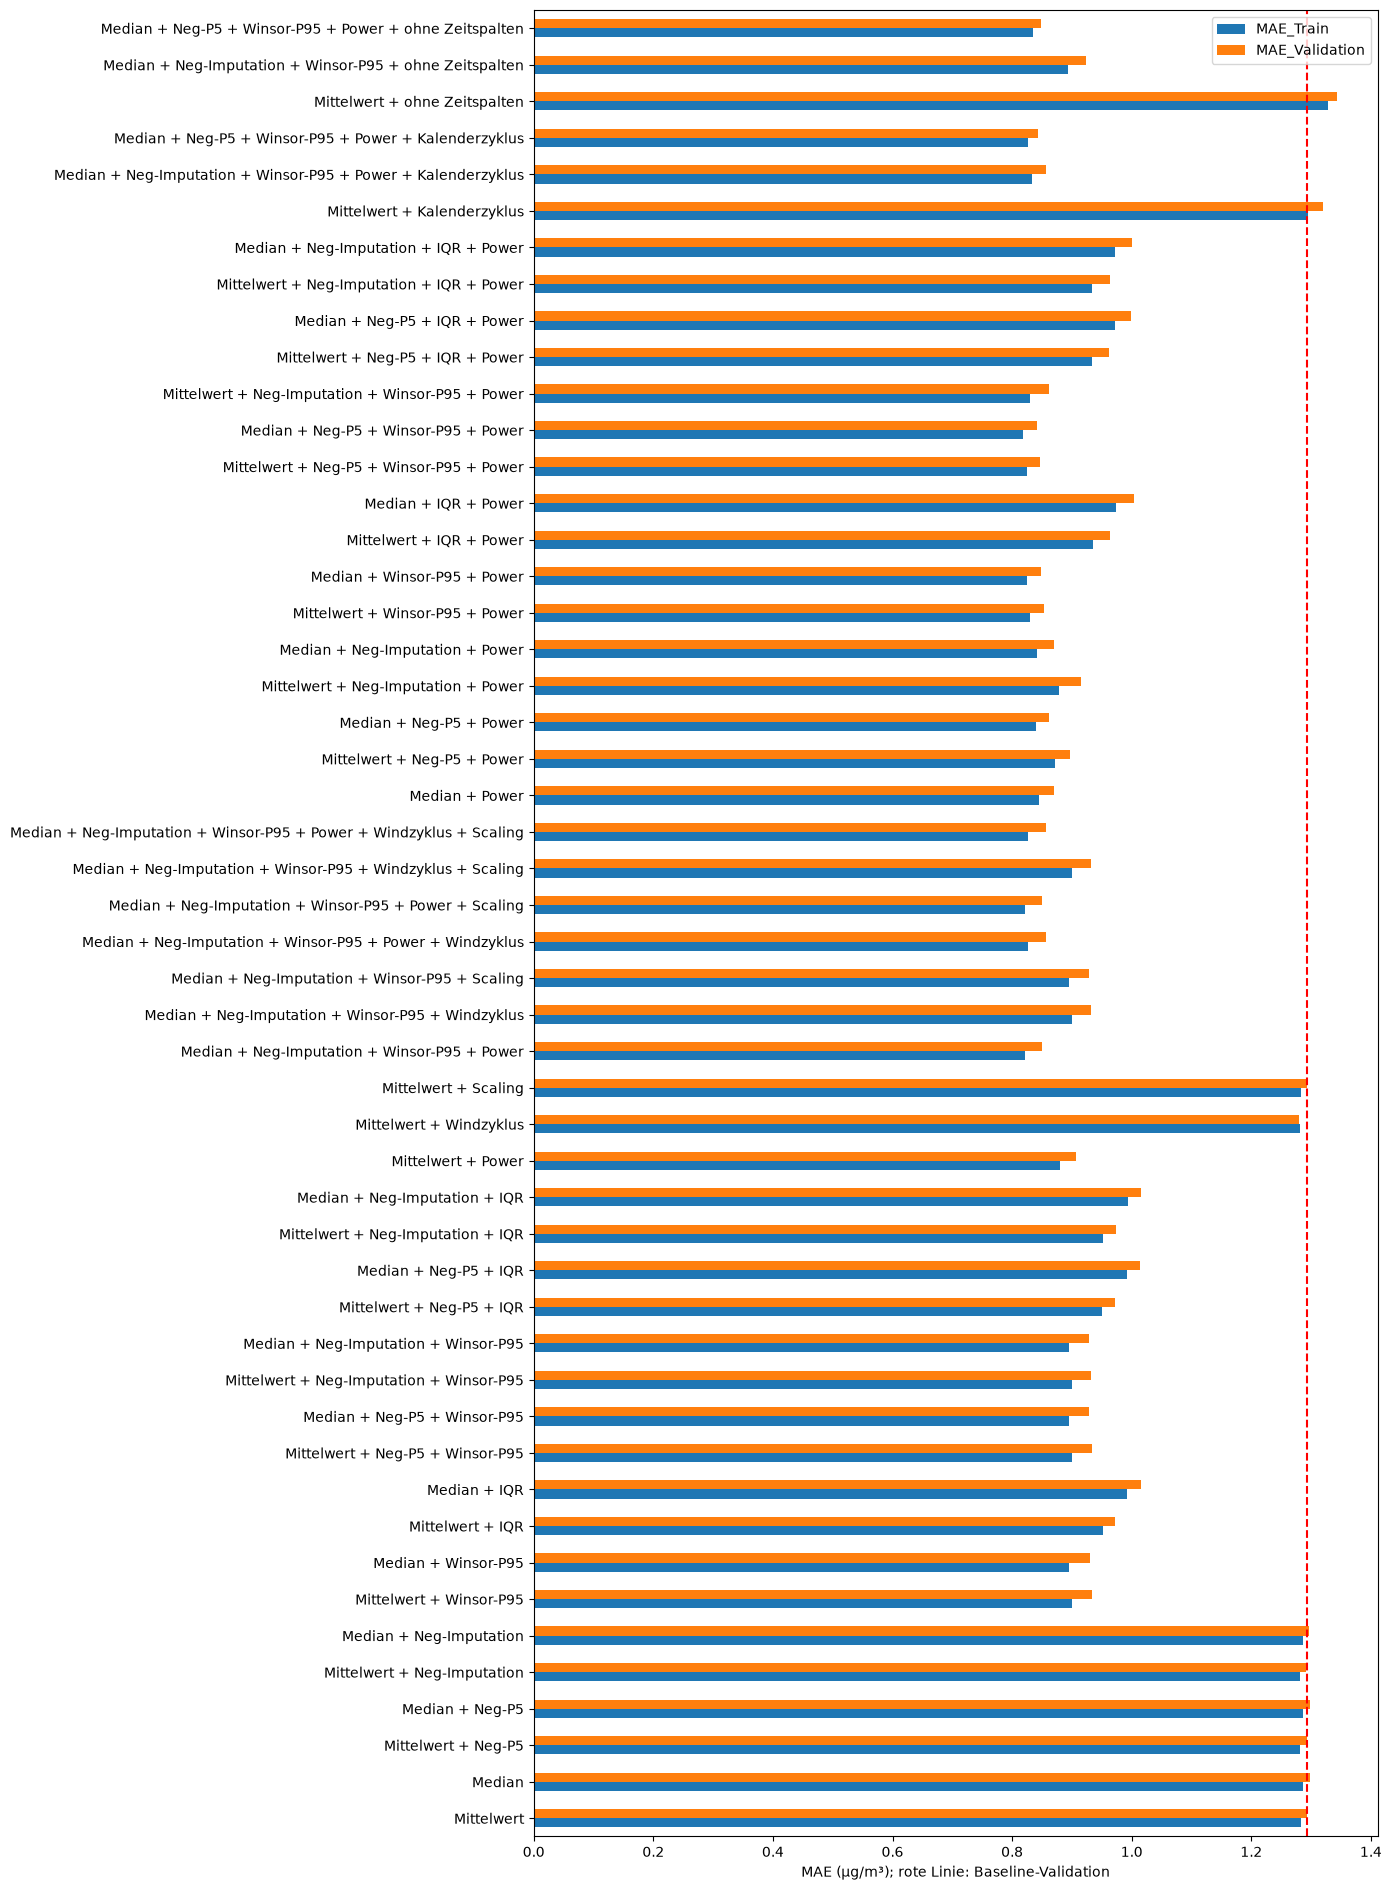

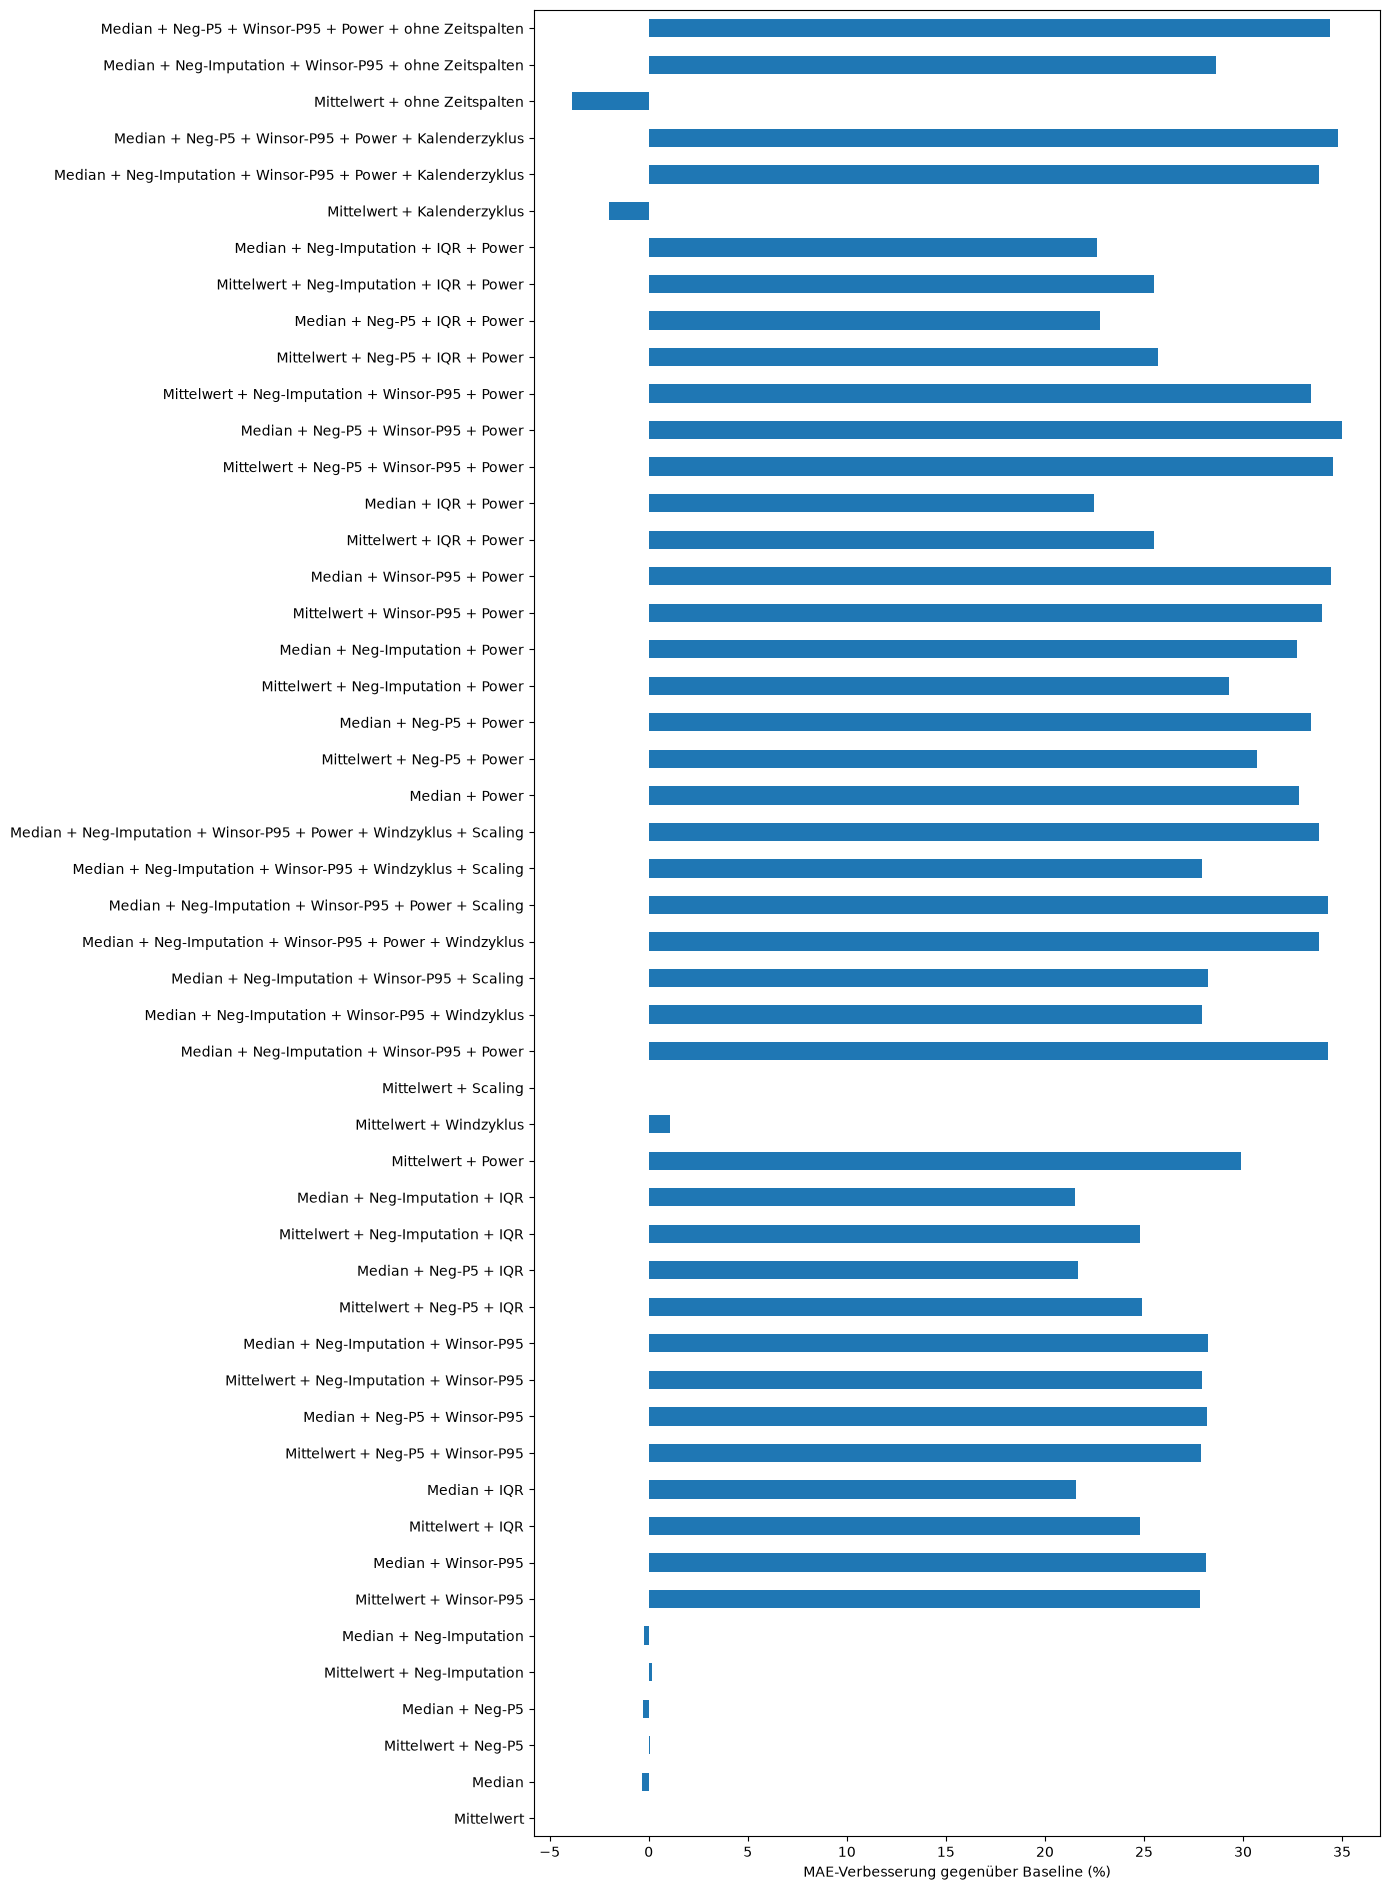

In [44]:
# Sammelt die protokollierten Modellkennzahlen in einer Vergleichstabelle; eine Zeile je Modell.
results = pd.DataFrame(log_results).T
results['MAE_Gewinn_abs'] = baseline_mae - results['MAE_Validation']
results['MAE_Gewinn_pct'] = 100 * results['MAE_Gewinn_abs'] / baseline_mae
results['R2_Delta'] = results['R2_Validation'] - baseline_r2
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert len(results) == 50
display(results.sort_values('MAE_Validation'))
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
results.to_csv('modellvergleich.csv', index_label='Modell')

# Zeigt die Ergebnisse als waagerechte Balken für einen direkten Vergleich.
results[['MAE_Train', 'MAE_Validation']].plot.barh(figsize=(14, 19))
# Markiert den Fehler der Baseline als senkrechte Vergleichslinie.
plt.axvline(baseline_mae, color='red', linestyle='--')
plt.xlabel('MAE (µg/m³); rote Linie: Baseline-Validation')
plt.tight_layout()
# Speichert das Diagramm zusätzlich als Bilddatei.
plt.savefig('modellvergleich_mae.png', bbox_inches='tight')
plt.show()
# Zeigt die Ergebnisse als waagerechte Balken für einen direkten Vergleich.
results['MAE_Gewinn_pct'].plot.barh(figsize=(14, 19))
plt.xlabel('MAE-Verbesserung gegenüber Baseline (%)')
plt.tight_layout()
# Speichert das Diagramm zusätzlich als Bilddatei.
plt.savefig('modellvergleich_delta.png', bbox_inches='tight')
plt.show()

## 20. Kombinationseffekt und Scaling einordnen

**Quelle:** Ergebnislog und Matplotlib des alten Projekts; zusätzliche einfache Subtraktionen erfüllen das Feedback zu Deltas und Kombinationen.

Positive MAE-Gewinne bedeuten Verbesserung. Die Differenz aus gemeinsamem Gewinn und Summe der Einzelgewinne zeigt, ob die Effekte additiv sind. Sie ist kein Kausalnachweis. Unregularisierte lineare Regression mit Intercept kann affine Skalierung durch andere Koeffizienten ausgleichen; deshalb ist hier kein systematischer Scaling-Gewinn zu erwarten.

In [45]:
gain_winsor = results.loc['Mittelwert + Winsor-P95', 'MAE_Gewinn_abs']
gain_p5 = results.loc['Mittelwert + Neg-P5', 'MAE_Gewinn_abs']
gain_both = results.loc['Mittelwert + Neg-P5 + Winsor-P95', 'MAE_Gewinn_abs']
print('Winsor-Gewinn:', gain_winsor)
print('Neg-P5-Gewinn:', gain_p5)
print('Gemeinsamer Gewinn:', gain_both)
print('Zusätzlicher Kombinationseffekt:', gain_both - gain_winsor - gain_p5)
print('MAE-Änderung durch Scaling allein:',
      results.loc['Mittelwert + Scaling', 'MAE_Validation'] - baseline_mae)
print('MAE-Änderung durch Scaling nach Core + Power:',
      results.loc[core_name + ' + Power + Scaling', 'MAE_Validation']
      - results.loc[core_name + ' + Power', 'MAE_Validation'])

Winsor-Gewinn: 0.36023517316828046
Neg-P5-Gewinn: 0.0006448787294794922
Gemeinsamer Gewinn: 0.36049804254141316
Zusätzlicher Kombinationseffekt: -0.0003820093563468019
MAE-Änderung durch Scaling allein: -1.9984014443252818e-15
MAE-Änderung durch Scaling nach Core + Power: -6.661338147750939e-16


## Ergebnis des Zeitspalten-Vergleichs

| Datenstand | Validation-MAE mit Zeitspalten | ohne Zeitspalten | Änderung durch Weglassen |
|---|---:|---:|---:|
| Vollständige Baseline | 1,293881 | 1,343886 | +0,050006 |
| Median + Neg-Imputation + P95 | 0,928889 | 0,923254 | −0,005635 |
| Median + Neg-P5 + P95 + Power | 0,841373 | 0,848958 | +0,007585 |

Ein kleinerer MAE ist besser. Das Entfernen hilft also leicht auf der Grundvorbereitung, aber nicht auf der Baseline oder der bislang besten Gesamtvariante. Das zeigt, weshalb Einzelmaßnahmen und Kombinationen getrennt geprüft werden müssen. Bei der Grundvorbereitung sinkt zwar der MAE, das Validation-R² verschlechtert sich von 0,6583 auf 0,6436; das festgelegte Auswahlkriterium bleibt MAE.

**Finale Auswahl aus 50 Varianten:** Median + Neg-P5 + Winsor-P95 + Power **mit Zeitfeatures**. Ihr Validation-MAE 0,841373 bleibt der kleinste untersuchte Wert. Der Ausschluss der Zeitspalten wurde durchgeführt und bewertet, aber nicht in die finalen CSVs übernommen. Damit wird nicht der bereits bekannte bessere Testwert der Variante ohne Zeitfeatures zum Auswahlkriterium gemacht.

Das ausgewählte Modell und die finalen Exporte bleiben deshalb inhaltlich unverändert: Test-MAE 2,193486 und Test-R² 0,038223. Die Einschränkung der schlechten zeitlichen Übertragbarkeit bleibt bestehen. Die drei neuen Kandidaten werden nicht zusätzlich auf dem Test zur Auswahl verglichen. Alle Zeilen und Zielwerte bleiben erhalten. Keine Präsentation erstellt.


## 21. Auswahl vor dem Test

**Quelle:** Task-1-Notebook, Zelle 19 (`idxmin` zur Auswahl); altes Projekt Zellen 34/36 (benannte Enddaten). **Anpassung:** Der Gewinner wird ausdrücklich benannt und anhand des Ergebnislogs geprüft; bei numerisch gleichem MAE wird die einfachere Variante ohne Scaling gewählt.

Für diese Daten wird die beste Grundvorbereitung mit Power-Transformation weiterverwendet. Die folgende Prüfung stoppt, falls bei einem geänderten Lauf eine andere Variante besser ist. Dann die Tabelle prüfen und die sichtbaren Variablen samt Testschritten anpassen. Kein Refit auf Training plus Validation, damit die Exporte für Task 3 getrennt bleiben.

In [46]:
best_name = 'Median + Neg-P5 + Winsor-P95 + Power'
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert results.loc[best_name, 'MAE_Validation'] <= results['MAE_Validation'].min() + 1e-8
final_model = model_p5_winsor_median_power
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
train_final = train_p5_winsor_median_power.copy()
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
val_final = val_p5_winsor_median_power.copy()
print('Ausgewählt:', best_name)
display(results.loc[[best_name]])
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
results.loc[['Mittelwert', best_name], ['MAE_Train','MAE_Validation','R2_Train','R2_Validation']].to_csv('baseline_und_auswahl.csv', index_label='Modell')

Ausgewählt: Median + Neg-P5 + Winsor-P95 + Power


,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-P5 + Winsor-P95 + Power,0.818871,0.731016,0.841373,0.728178,0.022503,0.452507,34.972888,0.316489


## 22. Finalen Test vorbereiten

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 36 (0-basiert).

**Originalstelle:**
```python
# Trainieren der Testdaten
test_M1 = rule_based(test_df)
test_M2 = missing_value(test_M1)
test_M3 = feature_removal(test_M2)
```

**Notwendige Anpassung:** Dieselbe explizite Folge benannter Funktionen; nur die tatsächlich ausgewählten Schritte. Ausschließlich bereits berechnete Trainingsgrenzen, Trainingsmedian und PowerTransformer verwenden.

In [47]:
# Liest die CSV-Datei als Tabelle ein. Die Datei muss neben dem Notebook liegen.
test_df = pd.read_csv('pm25_test.csv')
test_numeric = rule_based(test_df.drop(columns='pm25_target'))
_, test_raw = one_hot_and_align(train_numeric, test_numeric)
# Wendet die Negativwertkorrektur mit den festen Trainingsgrenzen an.
test_p5 = negative_p5(test_raw, p05)
# Kappt hohe PM2.5-Eingaben an derselben Trainingsgrenze; der Zielwert wird nicht gekappt.
test_p5_winsor = winsorisation(test_p5, p95)
# Füllt Lücken mit den zuvor berechneten Trainings-Ersatzwerten; auch Validation bekommt genau diese Werte.
test_core = missing_value(test_p5_winsor, median_p5_winsor)
# Überträgt dieselbe Umformung auf Validation oder Test, ohne deren Statistik zu lernen.
test_final = power_apply(test_core, pt_p5_winsor_median)
# Berechnet Vorhersagen. Die richtigen Antworten werden dabei nicht an das Modell übergeben.
test_pred = final_model.predict(test_final)

# Label nicht auffüllen: nur beobachtete Labels sind bewertbar (Task 1, Zelle 19).
# Kennzeichnet vorhandene Test-Zielwerte. Nur dort kann ein Fehler berechnet werden; alle Zeilen bleiben erhalten.
observed = test_df['pm25_target'].notna()
# MAE: durchschnittlicher Betrag des Vorhersagefehlers. Kleiner ist besser; Einheit hier µg/m³.
test_mae = mean_absolute_error(test_df.loc[observed, 'pm25_target'], test_pred[observed])
# R²: 1 ist perfekt, 0 entspricht der Vergleichsgüte des Zielmittelwerts; negative Werte sind möglich.
test_r2 = r2_score(test_df.loc[observed, 'pm25_target'], test_pred[observed])
print('Test-MAE:', test_mae, '| Test-R²:', test_r2)
print('Bewertbare Labels:', observed.sum(), 'von', len(test_df))
print('Unbekannte Monate:', set(test_df['year_month']) - set(train_df['year_month']))
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
pd.DataFrame({'Modell':[best_name], 'MAE':[test_mae], 'R2':[test_r2],
              'Zeilen':[len(test_df)], 'Labels':[observed.sum()]}).to_csv('test_ergebnis.csv',index=False)

Test-MAE: 2.193486345352524 | Test-R²: 0.038222758771245036
Bewertbare Labels: 1419 von 1464
Unbekannte Monate: {'2024-12', '2024-11'}


## 23. Drei CSVs exportieren

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 36 (0-basiert).

**Originalstelle:**
```python
train_M5_scaled.to_csv("Task2_Final_preprocessed_train_M5.csv", index=False)
test_M5_scaled.to_csv("Task2_Final_preprocessed_test_M5.csv", index=False)
```

**Notwendige Anpassung:** Zusätzlich Validation exportieren; unveränderte Labels aus den jeweiligen Originaldaten hinzufügen. Kein ID-Feature im Datensatz; Zeilenherkunft in separaten Dateien.

In [48]:
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
train_export = train_final.copy()
train_export['pm25_target'] = y_train
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
val_export = val_final.copy()
val_export['pm25_target'] = y_val
# Arbeitet mit einer eigenen Kopie, damit frühere Datenstände unverändert bleiben.
test_export = test_final.copy()
test_export['pm25_target'] = test_df['pm25_target']
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
train_export.to_csv('pm25_preprocessed_train.csv', index=False)
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
val_export.to_csv('pm25_preprocessed_validation.csv', index=False)
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
test_export.to_csv('pm25_preprocessed_test.csv', index=False)
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
test_df[['timestamp']].to_csv('zeilen_test.csv', index_label='source_row')
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
pd.DataFrame({'prediction':test_pred},index=test_df.index).to_csv('test_vorhersagen.csv',index_label='source_row')
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
p05.to_csv('trainingsgrenzen_p5.csv',header=['P5'])
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
pd.Series({'pm25_lowcost':p95}).to_csv('trainingsgrenze_p95.csv',header=['P95'])
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
median_p5_winsor.to_csv('trainingsmediane_final.csv',header=['Median'])
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
pd.Series(pt_p5_winsor_median.lambdas_,index=power_columns).to_csv('power_parameter.csv',header=['Lambda'])

## 24. Kurze notwendige Abgabekontrollen

**Zusätzlicher Prüfcode, keine behauptete Lab-Kopie.** Diese wenigen Prüfungen sichern die Aufgabenregeln: vollständige Validation/Test, unveränderte Labels und gleiche endliche Feature-Spalten. Die ausführlichen technischen Prüfungen der vorherigen Version sind nicht Teil dieses Lernnotebooks.

In [49]:
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert len(train_export) == 2727 and len(val_export) == 682 and len(test_export) == 1464
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert val_export['pm25_target'].equals(y_val)
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert test_export['pm25_target'].equals(test_df['pm25_target'])
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert train_export.columns.equals(val_export.columns)
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert train_export.columns.equals(test_export.columns)
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert np.isfinite(train_final.to_numpy()).all()
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert np.isfinite(val_final.to_numpy()).all()
# Sicherheitsprüfung: Falls diese Bedingung nicht stimmt, stoppt das Notebook.
assert np.isfinite(test_final.to_numpy()).all()
print('Kontrollen bestanden: Zeilen, Labels und Featureaufbau.')

Kontrollen bestanden: Zeilen, Labels und Featureaufbau.


## 25. Ergebnisse und Learnings

**Quelle:** das tatsächlich berechnete Ergebnislog; Ausgabe nach dem Muster des alten Projekts. Die Texte erläutern die Vergleiche, statt eine neue Auswertungsarchitektur einzuführen.

In [50]:
print('Beste der 50 untersuchten Varianten:', best_name)
print('Validation-MAE:', results.loc[best_name, 'MAE_Validation'])
print('Validation-R²:', results.loc[best_name, 'R2_Validation'])
print('MAE-Gewinn gegenüber derselben Baseline (%):', results.loc[best_name, 'MAE_Gewinn_pct'])
print('Training/Validation-MAE-Abstand:', results.loc[best_name, 'MAE_Gap'])
print('Finaler Test-MAE / R²:', test_mae, test_r2)

Beste der 50 untersuchten Varianten: Median + Neg-P5 + Winsor-P95 + Power
Validation-MAE: 0.8413732933589736
Validation-R²: 0.7281776338548323
MAE-Gewinn gegenüber derselben Baseline (%): 34.972887899241364
Training/Validation-MAE-Abstand: 0.022502716036406523
Finaler Test-MAE / R²: 2.193486345352524 0.038222758771245036


- Eine vollständige Baseline verhindert, dass eine künstlich schwache Featureauswahl als Vorbereitungserfolg erscheint.
- Die ungefilterte NO-P5-Grenze ist negativ. Eine Negativwertkorrektur darf deshalb nur gültige Trainingsmessungen als Referenz verwenden.
- Winsorisierung und IQR-Imputation sind verschiedene Eingriffe. Ihre Einzelwirkungen und Kombinationen werden auf demselben Split geprüft.
- Die stufenweise Auswahl ist lesbar, kann aber eine Kombination übersehen, deren Grundvorbereitung allein schwächer ist. Diese Version beansprucht keine globale Auswahl aus allen 144 früheren Kombinationen.
- Scaling ändert bei unregularisierter OLS den darstellbaren Modellraum nicht; Unterschiede in Rundungsgröße sind kein inhaltlicher Gewinn.
- Der Test war bereits bekannt. Zufällige zeitliche Mischung, mehrfach verwendete Validation und unbekannte Testmonate begrenzen die Übertragbarkeit. Geringes oder negatives Test-R² darf nicht durch gute Validierungswerte verdeckt werden.
- Keine Präsentation in dieser Abgabe. Die ältere Präsentation gehört nicht zum neuen Notebookstand.

### Frühere Ergebnisse als Ausgangspunkt

Der vorherige Stand mit 28 Varianten hatte Validation-MAE 0,849933 und Test-MAE 2,238649 (R² 0,011271). Die folgenden Diagnosen beziehen sich auf den neu ausgewählten Stand. Testdiagnosen sind beschreibend und ersetzen keine unabhängige Evaluation.

## 26. Ursachenanalyse des Testabstands

**Quellen:** Missing-Value-Demo, Zellen 9/10 (`describe`, `isnull`); altes Projekt Zellen 29/38 (Fehlerberechnung und Ergebnistabelle). **Zusätzlicher Analysecode:** Gruppierung von Residuen und Zerlegung der linearen Vorhersage mittels `coef_`. Diese Diagnose ist ausdrücklich keine unveränderte Lab-Kopie und kein neuer Preprocessing-Schritt. Sie dient der geforderten Interpretation. Es werden keine weiteren Modelle anhand des Tests ausgewählt.

Alle Teilgruppen sind nur Auswertungen; der vollständige Testexport bleibt erhalten. `Bias` bedeutet Vorhersage minus Zielwert. Der Zeitbeitrag ist ein algebraischer Modellanteil, kein kausaler Nachweis. Fehlquoten beruhen auf allen Eingabezeilen, Fehler nur auf vorhandenen Labels.

In [51]:
missing_comparison = pd.DataFrame({
    'Train_pct': 100 * train_df.isnull().mean(),
    'Validation_pct': 100 * val_df.isnull().mean(),
    'Test_pct': 100 * test_df.isnull().mean()})
display(missing_comparison)
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
missing_comparison.to_csv('diagnose_fehlquoten.csv', index_label='Spalte')

residuals = pd.DataFrame({'year_month': test_df['year_month'],
    'target': test_df['pm25_target'], 'prediction': test_pred,
    'Wetter_fehlt': test_df['temperature'].isnull(),
    'PM25_ueber_P95': test_df['pm25_lowcost'] > p95})
residuals['Fehler'] = residuals['prediction'] - residuals['target']
residuals['Absoluter_Fehler'] = residuals['Fehler'].abs()
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
residuals.to_csv('diagnose_test_residuen.csv', index_label='source_row')
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
for group in ['year_month', 'Wetter_fehlt', 'PM25_ueber_P95']:
    # Fasst Fehler nach Gruppen zusammen. Das dient nur der Diagnose; es werden keine Testzeilen gelöscht.
    grouped = residuals.loc[observed].groupby(group).agg(
        Anzahl=('target', 'count'), MAE=('Absoluter_Fehler', 'mean'),
        Bias=('Fehler', 'mean'))
    print(group)
    display(grouped)
    # Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
    grouped.to_csv('diagnose_' + group + '.csv')

# Liest die gelernten Gewichte aus: Sie beschreiben den Einfluss der Eingabespalten in diesem Modell.
coefficients = pd.Series(final_model.coef_, index=train_final.columns)
time_columns = ['timestamp'] + [c for c in train_final if c.startswith('year_month_')]
print('Zeitkoeffizienten:')
display(coefficients[time_columns])
time_effect = pd.DataFrame({
    'Train': (train_final[time_columns] * coefficients[time_columns]).sum(axis=1).describe(),
    'Validation': (val_final[time_columns] * coefficients[time_columns]).sum(axis=1).describe(),
    'Test': (test_final[time_columns] * coefficients[time_columns]).sum(axis=1).describe()})
display(time_effect)
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
time_effect.to_csv('diagnose_zeitanteil.csv')
# Speichert diese Tabelle als CSV. Sie kann später unabhängig vom Notebook geöffnet werden.
coefficients.to_csv('diagnose_koeffizienten.csv', header=['Koeffizient'])
print('Test-Bias:', residuals['Fehler'].mean())
print('P95 überschritten (Anteil aller Zeilen):',
      (train_df['pm25_lowcost'] > p95).mean(),
      (val_df['pm25_lowcost'] > p95).mean(),
      (test_df['pm25_lowcost'] > p95).mean())
print('Zeitbereiche:', train_df['timestamp'].min(), train_df['timestamp'].max(),
      test_df['timestamp'].min(), test_df['timestamp'].max())

,Train_pct,Validation_pct,Test_pct
timestamp,0.000000,0.000000,0.000000
year_month,0.000000,0.000000,0.000000
pm25_target,0.000000,0.000000,3.073770
pm25_lowcost,9.644298,9.237537,0.204918
no,0.476714,0.586510,0.136612
no2,0.476714,0.586510,0.136612
o3,21.488816,19.794721,10.655738
co2,27.722772,24.340176,58.606557
black_carbon,0.000000,0.000000,48.702186
ufp,16.795013,17.302053,42.008197


year_month


,Anzahl,MAE,Bias
year_month,,,
2024-11,675,1.774619,-1.542910
2024-12,744,2.573507,-2.386669


Wetter_fehlt


,Anzahl,MAE,Bias
Wetter_fehlt,,,
False,434,2.669846,-2.662734
True,985,1.983598,-1.686822


PM25_ueber_P95


,Anzahl,MAE,Bias
PM25_ueber_P95,,,
False,1165,1.865161,-1.644289
True,254,3.699387,-3.549408


Zeitkoeffizienten:


timestamp            -0.012372
year_month_2024-07   -0.008857
year_month_2024-08    0.250635
year_month_2024-09    1.414071
year_month_2024-10    0.779684
dtype: float64

,Train,Validation,Test
count,2727.000000,682.000000,1464.000000
mean,-0.442853,-0.427742,-2.239101
std,0.373695,0.357668,0.217938
min,-1.081809,-1.081293,-2.616194
25%,-0.736232,-0.709954,-2.427648
50%,-0.523655,-0.501585,-2.239101
75%,-0.093049,-0.105163,-2.050555
max,0.277380,0.276864,-1.862008


Test-Bias: -1.9853039806482928
P95 überschritten (Anteil aller Zeilen): 0.04547121378804547 0.04398826979472141 0.18032786885245902
Zeitbereiche: 2024-06-03 12:00:00 2024-10-31 23:00:00 2024-11-01 00:00:00 2024-12-31 23:00:00


## 27. Interpretation der Ursachenprüfung

## Ergebnis

Die Implementierung wurde kontrolliert: unveränderte Rohdaten, identischer Task-1-Split, Training-only-Parameter, passende Feature-Reihenfolge und unveränderte Zielwerte. Die final exportierten Daten reproduzieren die Vorhersagen. Ein Vertauschen von Zeilen oder erneutes Fitten auf Testdaten erklärt den Abstand nicht.

| Stand | MAE Training | MAE Validation | R² Validation | MAE Test | R² Test |
|---|---:|---:|---:|---:|---:|
| Bisher: Median + Neg-Imputation + P95 + Power | 0,8212 | 0,8499 | 0,7273 | 2,2386 | 0,0113 |
| Neu: Median + Neg-P5 + P95 + Power | 0,8189 | 0,8414 | 0,7282 | 2,1935 | 0,0382 |

Die Verbesserung gegenüber dem bisherigen Stand beträgt auf Validation rund 1,01 %, im Test rund 2,02 %. Diese kleinen Unterschiede sind kein Nachweis statistischer Signifikanz. Gegenüber der vollständigen Baseline (Validation-MAE 1,2939) verbessert sich der Validation-MAE um 34,97 %. Der Test bleibt schwach.

## Was den Testabstand erklärt – und was nicht bewiesen ist

**1. Zeitliche Extrapolation und unbekannte Monatskategorien.** Training und Validation enthalten Juni bis Oktober 2024; Test enthält November und Dezember. Der zufällige 80/20-Split prüft keine Vorhersage auf spätere Monate. Die bisherigen Monats-Dummies können neue Kategorien nicht lernen: Beide Testmonate werden beim Spaltenabgleich wie die Trainingsreferenz behandelt. Dazu kommt ein negativer linearer Tagestrend. Im neu ausgewählten Modell beträgt dessen Koeffizient −0,01237 pro Tag. Der kombinierte Zeitbeitrag zur Vorhersage beträgt durchschnittlich −0,443 im Training und −2,239 im Test, also rund 1,80 µg/m³ weniger. Die mittlere Testabweichung beträgt −1,985 µg/m³: Das Modell unterschätzt systematisch. Die Zerlegung belegt diesen Modellmechanismus, jedoch keinen isolierten kausalen Anteil am Testfehler; auch andere Eingaben und die Zielverteilung ändern sich.

**2. Andere Verfügbarkeit der Messdaten.** In den tatsächlich verwendeten Trainingszeilen fehlen Wetterdaten bei rund 11,4 %, im Test bei 67,3 %. Im ursprünglichen Trainingsfile sind es 11,8 %. CO₂ fehlt im Test bei 58,6 %, Black Carbon bei 48,7 %. Die Imputation bleibt korrekt auf Trainingswerte beschränkt, ersetzt im Test aber wesentlich mehr echte Information. Fehlende Wetterdaten allein erklären den Abstand nicht: Unter den bewertbaren Testzeilen beträgt der MAE mit vorhandenen Wetterdaten 2,670, bei fehlenden Wetterdaten 1,984. Diese Gruppen liegen in verschiedenen Zeitabschnitten und sind nicht als kontrollierter Vergleich zu verstehen.

**3. Die P95-Kappung greift im Test viel häufiger.** Die feste Trainingsgrenze beträgt 11,3155 µg/m³ für pm25_lowcost. Sie wird von 4,55 % aller Trainingszeilen und 18,03 % aller Testzeilen überschritten; fehlende Messwerte sind in diesen Nennern enthalten. Bei den 254 bewertbaren Testzeilen oberhalb der Grenze beträgt der MAE 3,699, in den übrigen 1.165 Zeilen 1,865. Hohe echte Belastungen können durch die Kappung an Information verlieren. Die Gruppenanalyse beweist nicht, dass die Kappung den gesamten Mehrfehler verursacht. Die Grenze wurde nicht anhand des Tests verändert.

**4. Andere Zielverteilung.** Der Zielmittelwert steigt von 3,330 im Training auf 3,909 im Test, die Standardabweichung von 2,206 auf 2,906. Die Zielwerte werden unverändert belassen. Der Fehler steigt im Test von November (MAE 1,775) auf Dezember (2,574). Ein kleiner Training-/Validation-Abstand schützt nicht vor solchen Verteilungsunterschieden.

## Welche Verbesserungen wurden geprüft?

Der bisherige stufenweise Vergleich hatte Power nur auf einzelnen Grundvorbereitungen geprüft. Jetzt wird Power mit allen 18 Grundvorbereitungen verglichen. Dazu kommen drei begründete Kalenderdarstellungen: Baseline, bisherige Auswahl und neue P5-Kombination. Mit den drei ergänzten Zeitspalten-Vergleichen sind es insgesamt 50 Varianten, weiterhin keine vollständige Suche über alle Möglichkeiten.

Die Kalenderalternative verwendet ausschließlich die vorhandene Logik: Datumsableitungen aus dem alten Projekt (Zelle 7), Sinus/Cosinus aus dem Transformations-Lab (Zelle 16). Timestamp wird durch Stunde/Wochentag, year_month durch zyklischen Monat repräsentiert. Alle übrigen Features bleiben erhalten. Die Kalenderalternative erreicht auf der neuen P5-Kombination Validation-MAE 0,8439, gegenüber 0,8414 mit bisheriger Zeitdarstellung. Sie wird nach dem festgelegten MAE-Kriterium nicht übernommen und nicht separat auf dem Test bewertet.

Die neue Auswahl verwendet dieselben bereits vorhandenen Funktionen und LinearRegression. Nur P5 statt Negativwert-Imputation wird übernommen. Es wird kein neues Modellverfahren eingeführt. Das Entfernen der Zeitspalten wird zusätzlich als eigener Schritt geprüft, aber nicht in die finale Variante übernommen. Grenzen, Mediane und PowerTransformer stammen weiterhin nur aus Training. Kein Testlabel und keine Testzeile wird verändert oder entfernt.

## Grenzen und Konsequenz

Der bekannte Test wurde zur Diagnose genutzt; die Kalenderidee wurde danach formuliert. Auswahl über Validation ist notwendig, stellt aber keinen unberührten Test wieder her. Auch Validation wurde mehrfach verwendet. Es gibt daher keinen belastbaren Nachweis, dass die kleine Verbesserung auf neuen Daten anhält.

Eine zeitlich getrennte Zusatzvalidierung wäre für die spätere Anwendung aussagekräftiger; sie ersetzt hier ausdrücklich nicht den vereinbarten Task-1-Split. Um das Testproblem zuverlässig zu lösen, wären eine neue unabhängige spätere Prüfperiode und bessere Messdatenabdeckung nötig. Änderungen von Modellklasse gehören in Task 3. Testabhängige Quantile, Korrektur der Vorhersagen um den beobachteten Test-Bias oder Auswahl anhand besserer Testwerte wären keine saubere Lösung.

Die Abgabe berichtet deshalb die kleine regelkonforme Verbesserung und die verbleibende schlechte Übertragbarkeit offen. Keine Präsentation erstellt.
